## ========================================
### : SETUP & DATA DOWNLOAD
## ========================================
### Purpose: Download the WPW dataset from Kaggle and verify files


In [16]:

import kagglehub
import os

print("=" * 80)
print("STEP 1: DOWNLOADING WPW DATASET FROM KAGGLE")
print("=" * 80)

# Download latest version
path = kagglehub.dataset_download("bjoernjostein/wolfparkinsonwhitedata")
print(f"\n✅ Dataset downloaded to: {path}")

# Set dataset path
DATASET_PATH = "/home/jovyan/.cache/kagglehub/datasets/bjoernjostein/wolfparkinsonwhitedata/versions/1"
BASE_PATH = os.path.join(DATASET_PATH, "wpw_dataset")

# Verify files
all_files = os.listdir(BASE_PATH)
mat_files = [f for f in all_files if f.endswith(".mat")]
hea_files = [f for f in all_files if f.endswith(".hea")]

print(f"\n📊 Dataset Contents:")
print(f"   - Total .mat files (ECG signals): {len(mat_files)}")
print(f"   - Total .hea files (metadata): {len(hea_files)}")
print(f"\n✅ Setup complete! Ready for data exploration.")
print("=" * 80)

STEP 1: DOWNLOADING WPW DATASET FROM KAGGLE

✅ Dataset downloaded to: /home/jovyan/.cache/kagglehub/datasets/bjoernjostein/wolfparkinsonwhitedata/versions/1

📊 Dataset Contents:
   - Total .mat files (ECG signals): 160
   - Total .hea files (metadata): 160

✅ Setup complete! Ready for data exploration.



### : DATA EXPLORATION & VISUALIZATION
### ========================================
### Purpose: Understand the raw ECG signals and metadata structure

STEP 2: EXPLORING RAW ECG DATA

📊 Analyzing sample file: JS36160.mat
--------------------------------------------------------------------------------

✅ Signal Structure:
   - Number of samples: 5000
   - Number of leads: 12
   - Duration: 10.00 seconds (@ 500 Hz)
   - Value range: [-2098.00, 2206.00] mV

📈 Visualizing ECG signals...
✅ Saved visualization: 'wpw_raw_signal_preview.png'


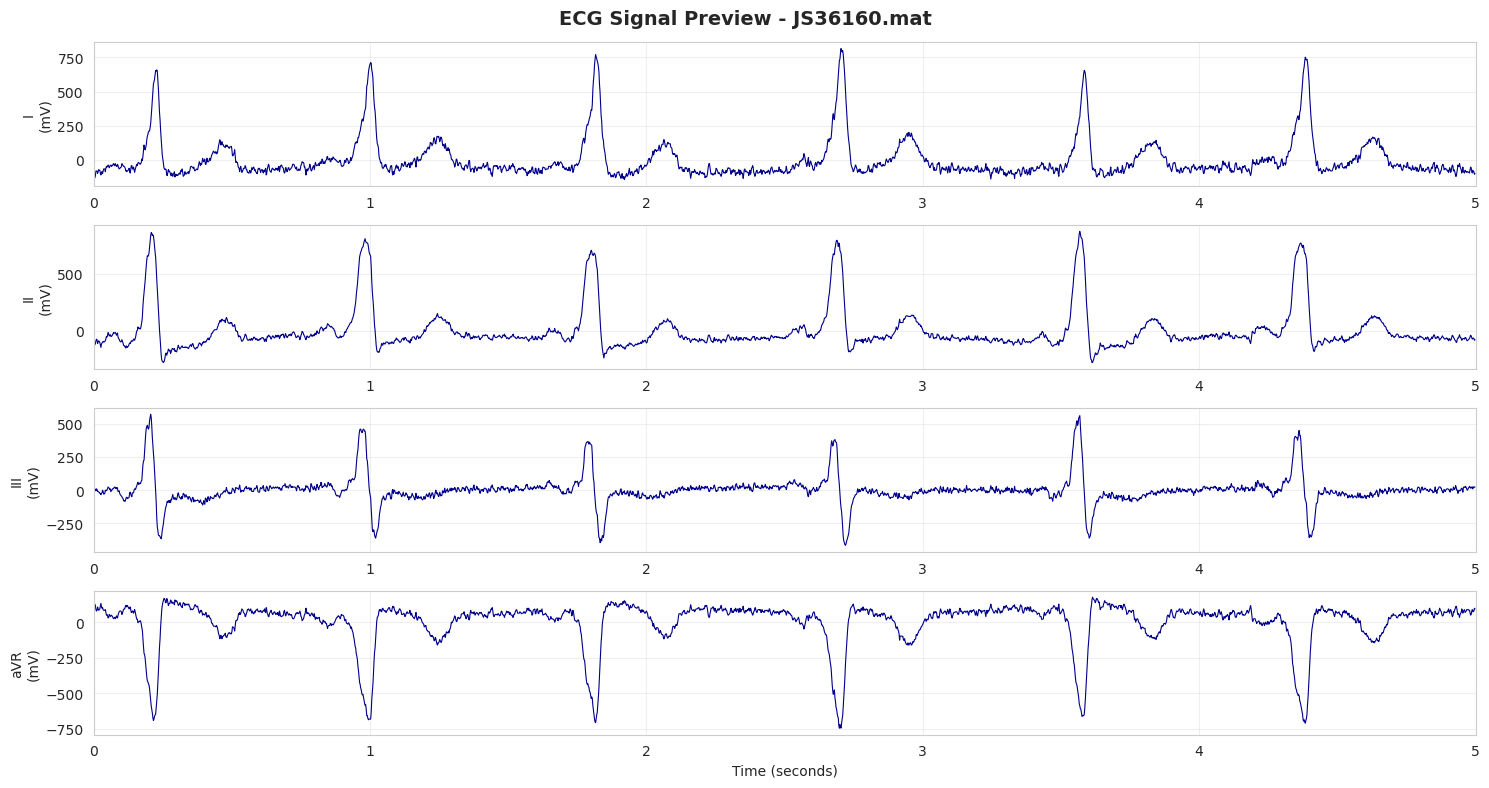


ANALYZING HEADER FILES (.hea)

📄 Sample header file: JS10034.hea

✅ Header contents:
   JS10034 12 500 5000 24-Mar-2021 07:17:24
   JS10034.mat 16+24 1000/mV 16 0 200 -23246 0 I
   JS10034.mat 16+24 1000/mV 16 0 -29 11057 0 II
   JS10034.mat 16+24 1000/mV 16 0 -229 -31226 0 III
   JS10034.mat 16+24 1000/mV 16 0 -83 -20614 0 aVR
   JS10034.mat 16+24 1000/mV 16 0 215 30701 0 aVL
   JS10034.mat 16+24 1000/mV 16 0 -132 -16206 0 aVF
   JS10034.mat 16+24 1000/mV 16 0 -508 8318 0 V1
   JS10034.mat 16+24 1000/mV 16 0 -195 -6775 0 V2
   JS10034.mat 16+24 1000/mV 16 0 205 -3064 0 V3
   JS10034.mat 16+24 1000/mV 16 0 307 -18517 0 V4
   JS10034.mat 16+24 1000/mV 16 0 234 10316 0 V5
   JS10034.mat 16+24 1000/mV 16 0 146 -23328 0 V6
   #Age: 37
   #Sex: Female
   #Dx: 426761007,164909002,74390002
   #Rx: Unknown
   #Hx: Unknown
   #Sx: Unknown

✅ Data exploration complete!


In [17]:


import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

print("=" * 80)
print("STEP 2: EXPLORING RAW ECG DATA")
print("=" * 80)

# ===============================
# ANALYZE .MAT FILES (RAW SIGNALS)
# ===============================
mat_files = [f for f in os.listdir(BASE_PATH) if f.endswith(".mat")]
sample_mat = mat_files[0]

print(f"\n📊 Analyzing sample file: {sample_mat}")
print("-" * 80)

# Load signal data
filepath = os.path.join(BASE_PATH, sample_mat)
data = loadmat(filepath)

# Extract ECG signal
signal_keys = [k for k in data.keys() if not k.startswith("__")]
raw_signal = data[signal_keys[0]]

# Fix dimensions if needed
if raw_signal.shape[1] > raw_signal.shape[0]:
    raw_signal = raw_signal.T

n_samples, n_channels = raw_signal.shape

print(f"\n✅ Signal Structure:")
print(f"   - Number of samples: {n_samples}")
print(f"   - Number of leads: {n_channels}")
print(f"   - Duration: {n_samples / 500:.2f} seconds (@ 500 Hz)")
print(f"   - Value range: [{np.min(raw_signal):.2f}, {np.max(raw_signal):.2f}] mV")

# ===============================
# VISUALIZE ECG LEADS
# ===============================
print(f"\n📈 Visualizing ECG signals...")

lead_names = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

fig, axes = plt.subplots(4, 1, figsize=(15, 8))
time = np.arange(min(2500, n_samples)) / 500  # First 5 seconds

for i in range(4):
    lead_name = lead_names[i]
    signal_segment = raw_signal[:min(2500, n_samples), i]
    
    axes[i].plot(time, signal_segment, linewidth=0.8, color='darkblue')
    axes[i].set_ylabel(f'{lead_name}\n(mV)', fontsize=10)
    axes[i].grid(True, alpha=0.3)
    axes[i].set_xlim(0, 5)
    
    if i == 3:
        axes[i].set_xlabel('Time (seconds)', fontsize=10)

fig.suptitle(f'ECG Signal Preview - {sample_mat}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('wpw_raw_signal_preview.png', dpi=300, bbox_inches='tight')
print(f"✅ Saved visualization: 'wpw_raw_signal_preview.png'")
plt.show()

# ===============================
# ANALYZE .HEA FILES (METADATA)
# ===============================
print("\n" + "=" * 80)
print("ANALYZING HEADER FILES (.hea)")
print("=" * 80)

hea_files = [f for f in os.listdir(BASE_PATH) if f.endswith(".hea")]
sample_hea = hea_files[0]

print(f"\n📄 Sample header file: {sample_hea}")
filepath = os.path.join(BASE_PATH, sample_hea)

with open(filepath, 'r') as f:
    lines = f.readlines()

print(f"\n✅ Header contents:")
for line in lines:
    print(f"   {line.rstrip()}")

print("\n✅ Data exploration complete!")
print("=" * 80)

## ========================================
### : FEATURE EXTRACTION
## ========================================
### Purpose: Extract clinical features from raw ECG signals

In [18]:

import pandas as pd
from scipy.signal import find_peaks

print("=" * 80)
print("STEP 3: EXTRACTING FEATURES FROM ECG SIGNALS")
print("=" * 80)

# ===============================
# HELPER FUNCTIONS
# ===============================

def load_mat(mat_path):
    """Load ECG signal from .mat file"""
    data = loadmat(mat_path)
    ecg = data['val']  # shape (12, 5000)
    return ecg.T       # transpose → (5000, 12)

def load_hea(hea_path):
    """Load metadata from .hea file"""
    meta = {}
    with open(hea_path, 'r') as f:
        lines = f.readlines()
    
    meta['record_id'] = lines[0].split()[0]
    
    for line in lines:
        if line.startswith("#Age:"):
            meta["age"] = int(line.split(":")[1].strip())
        elif line.startswith("#Sex:"):
            meta["sex"] = line.split(":")[1].strip()
        elif line.startswith("#Dx:"):
            meta["dx"] = line.split(":")[1].strip()
    
    return meta

def extract_features(ecg, fs=500):
    """Extract clinical features from ECG signal"""
    features = {}
    
    # Use Lead II for R-peak detection
    lead = ecg[:, 1]
    
    # Detect R-peaks (minimum distance 0.4s between peaks)
    peaks, _ = find_peaks(lead, distance=int(0.4 * fs))
    rr_intervals = np.diff(peaks) / fs  # RR intervals in seconds
    hr = 60 / rr_intervals if len(rr_intervals) > 0 else np.array([0])
    
    # Heart Rate features
    features['hr_mean'] = np.mean(hr) if len(hr) > 0 else 0
    features['hr_std'] = np.std(hr) if len(hr) > 0 else 0
    features['hr_max'] = np.max(hr) if len(hr) > 0 else 0
    
    # Heart Rate Variability (HRV) features
    features['hrv_sdnn'] = np.std(rr_intervals) if len(rr_intervals) > 0 else 0
    features['hrv_rmssd'] = np.sqrt(np.mean(np.diff(rr_intervals)**2)) if len(rr_intervals) > 1 else 0
    features['hrv_pnn50'] = (np.sum(np.abs(np.diff(rr_intervals)) > 0.05) / len(rr_intervals) * 100) if len(rr_intervals) > 1 else 0
    
    # QRS duration (approximate using half-max width)
    qrs_durations = []
    for p in peaks:
        left = p
        right = p
        while left > 0 and lead[left] > 0.5 * lead[p]:
            left -= 1
        while right < len(lead) - 1 and lead[right] > 0.5 * lead[p]:
            right += 1
        qrs_durations.append((right - left) / fs * 1000)  # Convert to ms
    
    features['qrs_duration_ms'] = np.mean(qrs_durations) if len(qrs_durations) > 0 else 0
    
    # QRS amplitude
    qrs_amp = []
    for p in peaks:
        window = lead[max(0, p-5):min(len(lead), p+6)]
        qrs_amp.append(np.max(window) - np.min(window))
    
    features['qrs_amplitude'] = np.mean(qrs_amp) if len(qrs_amp) > 0 else 0
    
    # Signal statistics
    features['signal_range'] = np.max(ecg) - np.min(ecg)
    features['signal_std'] = np.std(ecg)
    
    return features

# ===============================
# PROCESS ALL FILES
# ===============================
print("\n🔄 Processing all ECG records...")

records = []
processed = 0

for fname in os.listdir(BASE_PATH):
    if fname.endswith(".mat"):
        record_id = fname.split(".")[0]
        mat_path = os.path.join(BASE_PATH, f"{record_id}.mat")
        hea_path = os.path.join(BASE_PATH, f"{record_id}.hea")
        
        # Load data
        ecg = load_mat(mat_path)
        meta = load_hea(hea_path)
        
        # Extract features
        feats = extract_features(ecg)
        
        # Combine metadata and features
        row = {**meta, **feats}
        records.append(row)
        
        processed += 1
        if processed % 50 == 0:
            print(f"   Processed {processed} records...")

# ===============================
# CREATE DATAFRAME & SAVE
# ===============================
df = pd.DataFrame(records)

# Set all records to WPW positive (dx=1)
df["dx"] = 1

# Save to CSV
OUTPUT_CSV = "wpw_dataset_features.csv"
df.to_csv(OUTPUT_CSV, index=False)

print(f"\n✅ Feature extraction complete!")
print(f"   - Total records processed: {len(df)}")
print(f"   - Features extracted per record: {len(df.columns) - 1}")
print(f"   - Saved to: {OUTPUT_CSV}")

# Display sample
print(f"\n📊 Sample of extracted features:")
print(df.head())
print("\n" + "=" * 80)

STEP 3: EXTRACTING FEATURES FROM ECG SIGNALS

🔄 Processing all ECG records...
   Processed 50 records...
   Processed 100 records...
   Processed 150 records...

✅ Feature extraction complete!
   - Total records processed: 160
   - Features extracted per record: 13
   - Saved to: wpw_dataset_features.csv

📊 Sample of extracted features:
  record_id  age     sex  dx     hr_mean     hr_std      hr_max  hrv_sdnn  \
0   JS36160   40  Female   1  128.790543  23.574015  148.514851  0.129130   
1   HR07407   47    Male   1   81.512301   0.790141   83.102493  0.007080   
2   HR20486   54  Female   1  136.489773   9.168301  150.000000  0.030503   
3   HR04658   59  Female   1  137.265660   6.655315  144.927536  0.022164   
4   HR15183   64    Male   1  142.520682   4.838566  150.000000  0.014340   

   hrv_rmssd  hrv_pnn50  qrs_duration_ms  qrs_amplitude  signal_range  \
0   0.188542  35.000000        29.619048      85.428571          4304   
1   0.007348   0.000000        31.428571     377.000

## ========================================
### : DATA MERGING & PREPARATION
## ========================================
### Purpose: Merge WPW and normal ECG datasets, prepare for modeling

STEP 4: MERGING DATASETS & PREPROCESSING

📥 Loading datasets...
   - WPW records: 160
   - Normal records: 160

🔧 Harmonizing column names...
   ✅ Column alignment complete

🔀 Merging datasets...
   ✅ Merged dataset size: 320 records
   - WPW positive (dx=1): 160
   - Normal (dx=0): 160

🧹 Preprocessing data...
   ✅ Sex encoding complete
   ✅ Missing values filled
   ✅ HRV features log-transformed

💾 Saved merged dataset: merged_cleanest_ecg.csv

DATASET SUMMARY

Shape: (320, 14)

Class distribution:
dx
1    160
0    160
Name: count, dtype: int64

Feature statistics:
             age          dx     hr_mean      hr_std      hr_max    hrv_sdnn  \
count  320.00000  320.000000  320.000000  320.000000  320.000000  320.000000   
mean    48.18125    0.500000  115.988795   16.502350  141.250497    0.077997   
std     17.60321    0.500783   16.433654    8.348097   16.504630    0.043729   
min      0.00000    0.000000   77.149976    0.201530   79.365079    0.001895   
25%     37.75000    0.0000

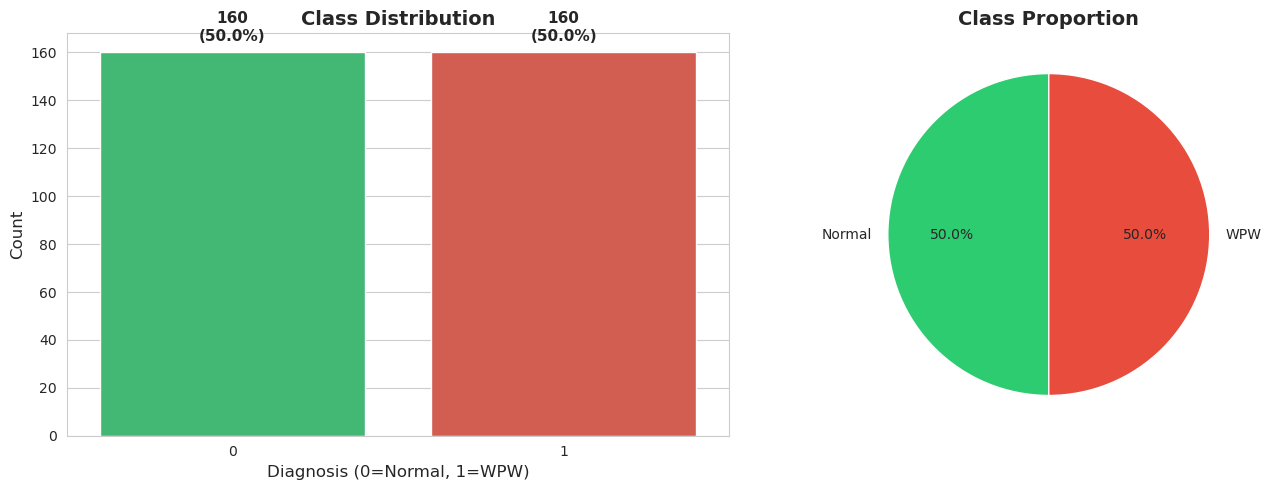


📊 SECTION 3: DEMOGRAPHIC FEATURES
--------------------------------------------------------------------------------

🔹 AGE DISTRIBUTION:
    count     mean        std  min    25%   50%   75%   max
dx                                                         
0   160.0  50.2875  16.348172  0.0  39.75  51.0  63.0  81.0
1   160.0  46.0750  18.587732  4.0  35.50  48.0  60.0  85.0

🔹 SEX DISTRIBUTION:
sex      0      1      0     1
dx                            
0    78.75  21.25   0.00   0.0
1     0.00   1.25  41.25  57.5


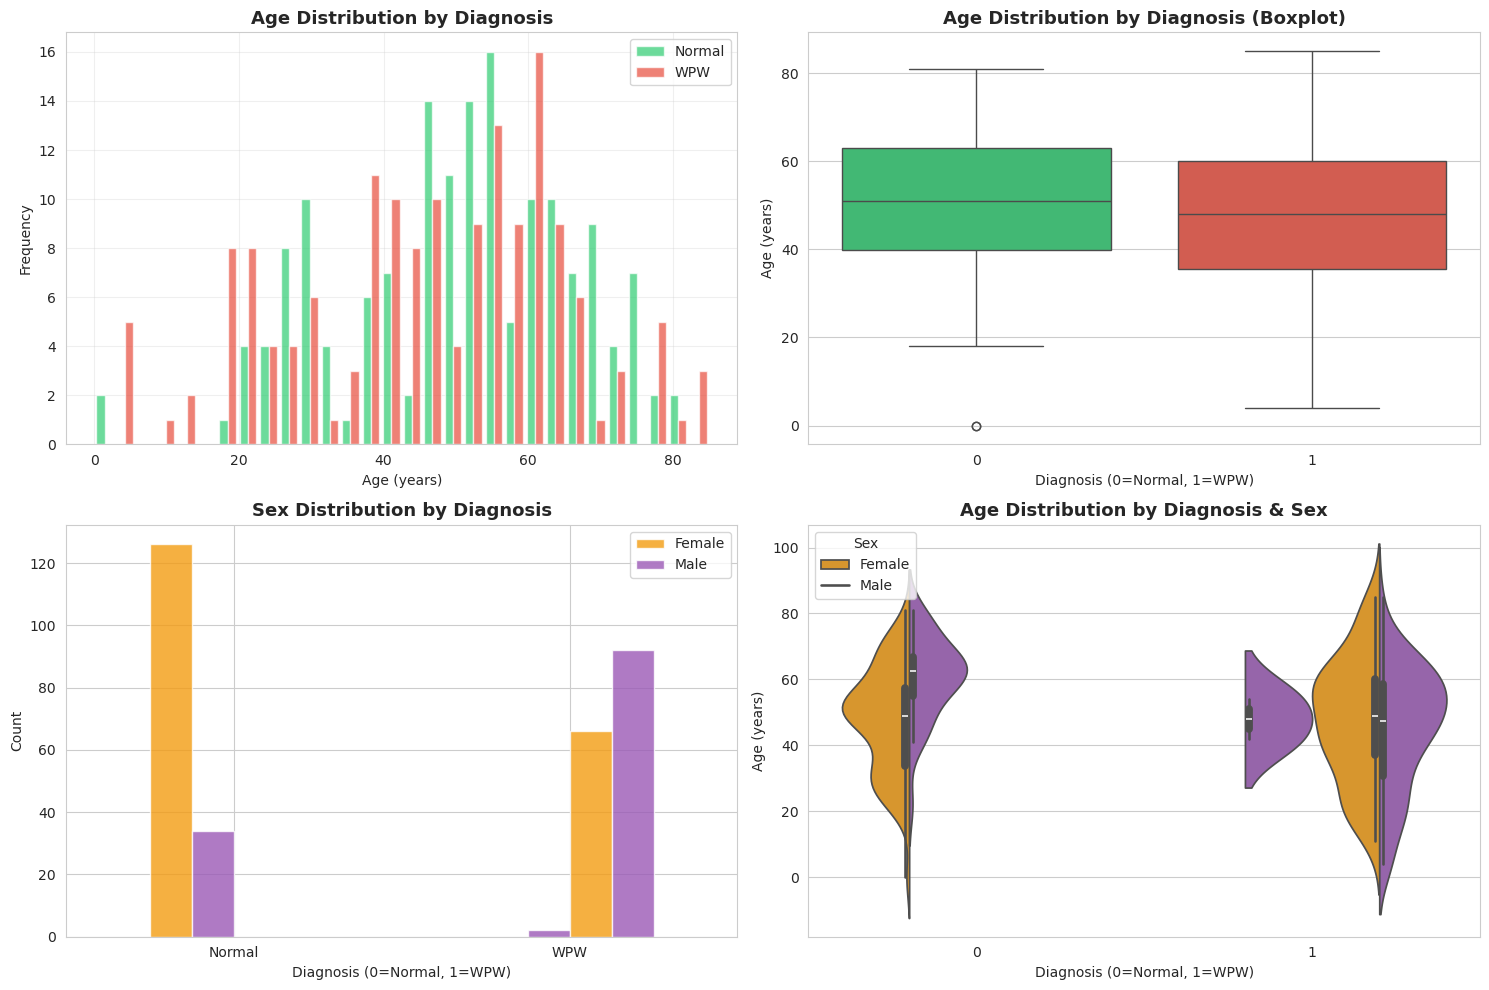


📈 T-test for age difference: t=2.153, p=0.0321

📊 SECTION 4: HEART RATE METRICS
--------------------------------------------------------------------------------

📊 SECTION 5: HEART RATE VARIABILITY (HRV)
--------------------------------------------------------------------------------

🔹 Found 3 HRV features:
['hrv_sdnn', 'hrv_rmssd', 'hrv_pnn50']

🔹 HRV STATISTICS BY DIAGNOSIS:
   hrv_sdnn                                                              \
      count      mean       std       min       25%       50%       75%   
dx                                                                        
0     160.0  0.076166  0.043427  0.001895  0.042662  0.067306  0.099968   
1     160.0  0.079828  0.044089  0.002868  0.049418  0.079255  0.111275   

             hrv_rmssd            ...                     hrv_pnn50  \
         max     count      mean  ...       75%       max     count   
dx                                ...                                 
0   0.186138     160.0  0.098

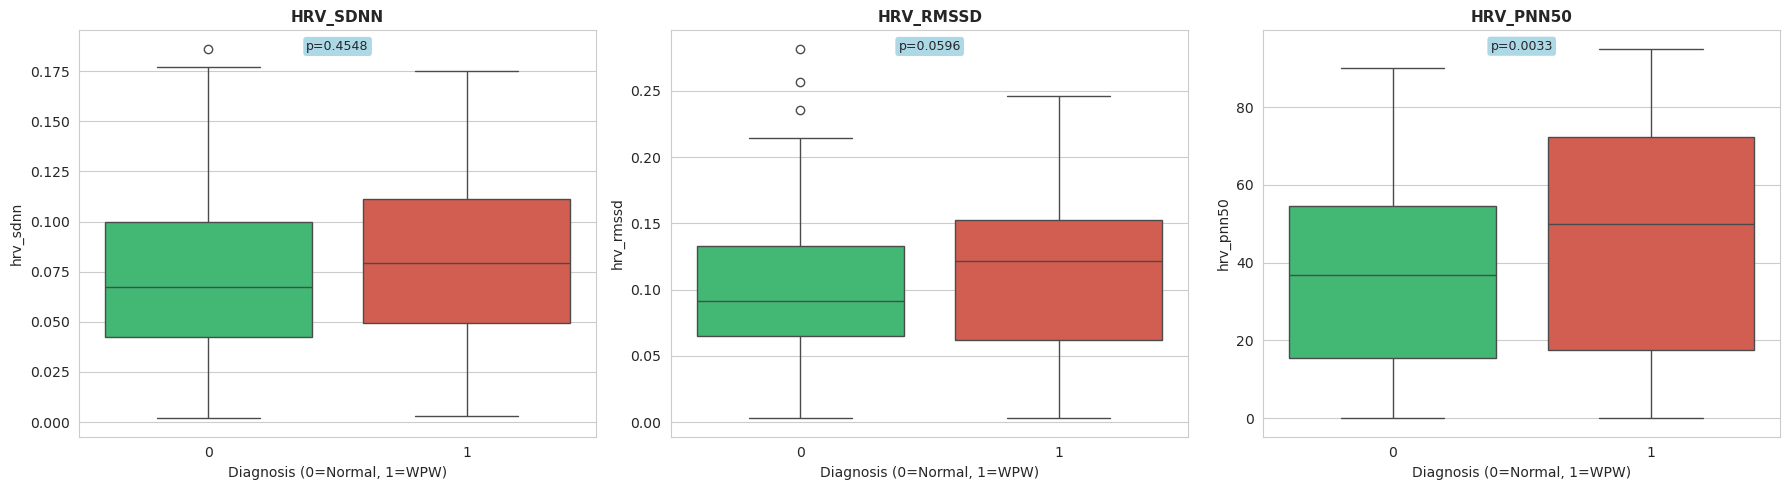


📊 SECTION 6: FEATURE CORRELATION ANALYSIS
--------------------------------------------------------------------------------

🔹 TOP 15 FEATURES CORRELATED WITH DIAGNOSIS:
signal_range       0.564701
signal_std         0.518951
hrv_pnn50          0.163989
qrs_duration_ms    0.116697
hrv_rmssd          0.105415
hrv_sdnn           0.041930
hr_std             0.040822
hr_max            -0.073226
hr_mean           -0.115899
age               -0.119839
qrs_amplitude     -0.127591
Name: dx, dtype: float64

🔹 BOTTOM 15 FEATURES CORRELATED WITH DIAGNOSIS:
signal_range       0.564701
signal_std         0.518951
hrv_pnn50          0.163989
qrs_duration_ms    0.116697
hrv_rmssd          0.105415
hrv_sdnn           0.041930
hr_std             0.040822
hr_max            -0.073226
hr_mean           -0.115899
age               -0.119839
qrs_amplitude     -0.127591
Name: dx, dtype: float64


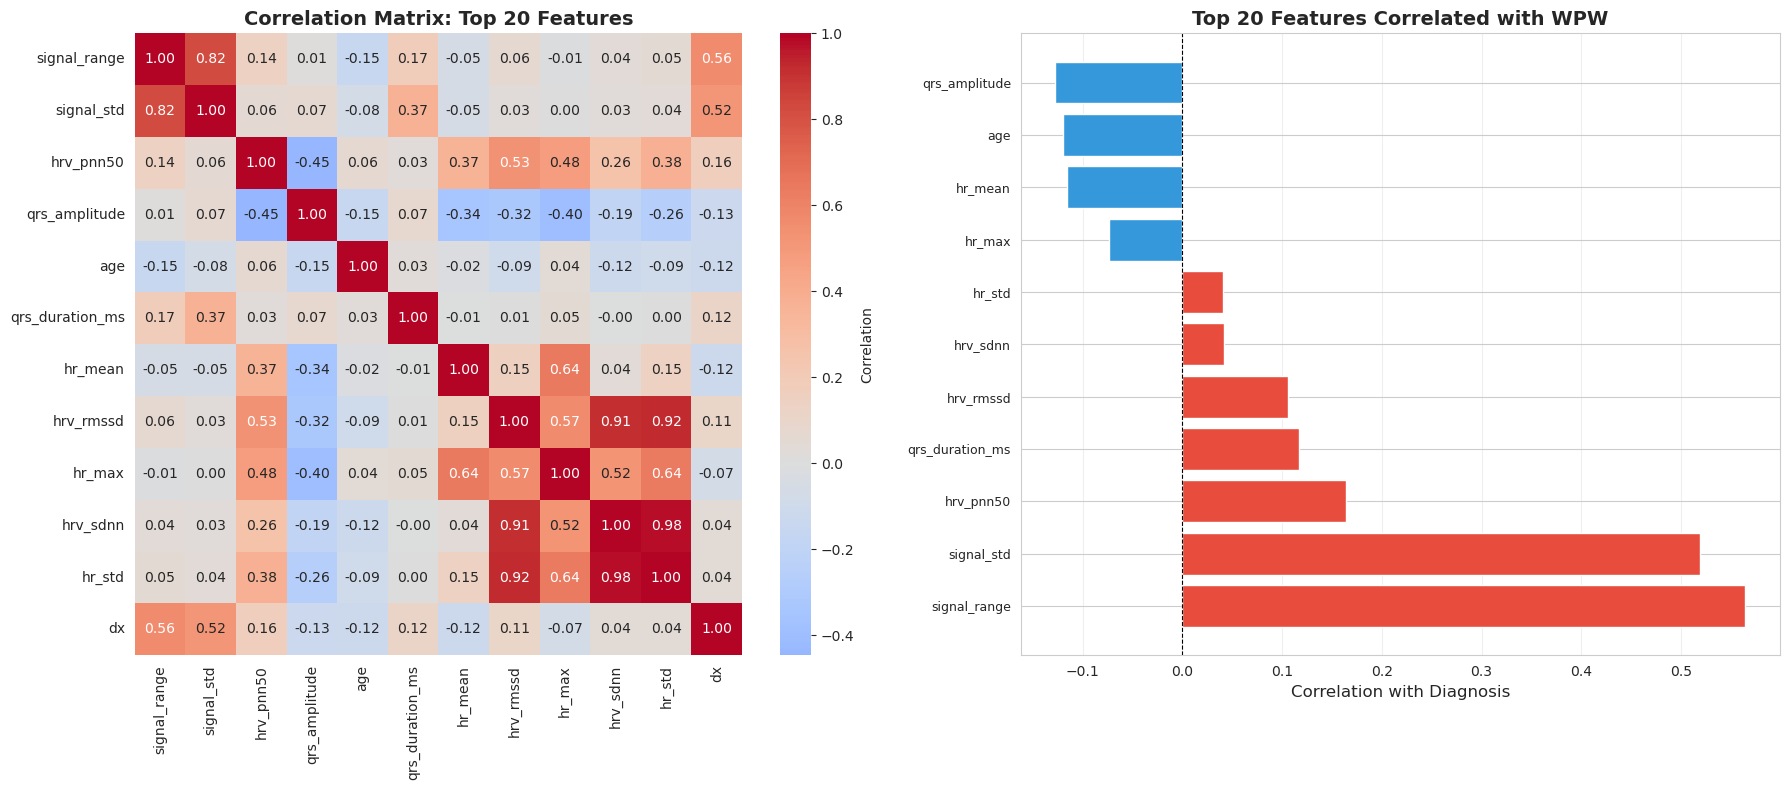


📊 SECTION 7: FEATURE DISTRIBUTION ANALYSIS
--------------------------------------------------------------------------------

🔹 Analyzing distributions for top 10 correlated features:
['signal_range', 'signal_std', 'hrv_pnn50', 'qrs_amplitude', 'age', 'qrs_duration_ms', 'hr_mean', 'hrv_rmssd', 'hr_max', 'hrv_sdnn']


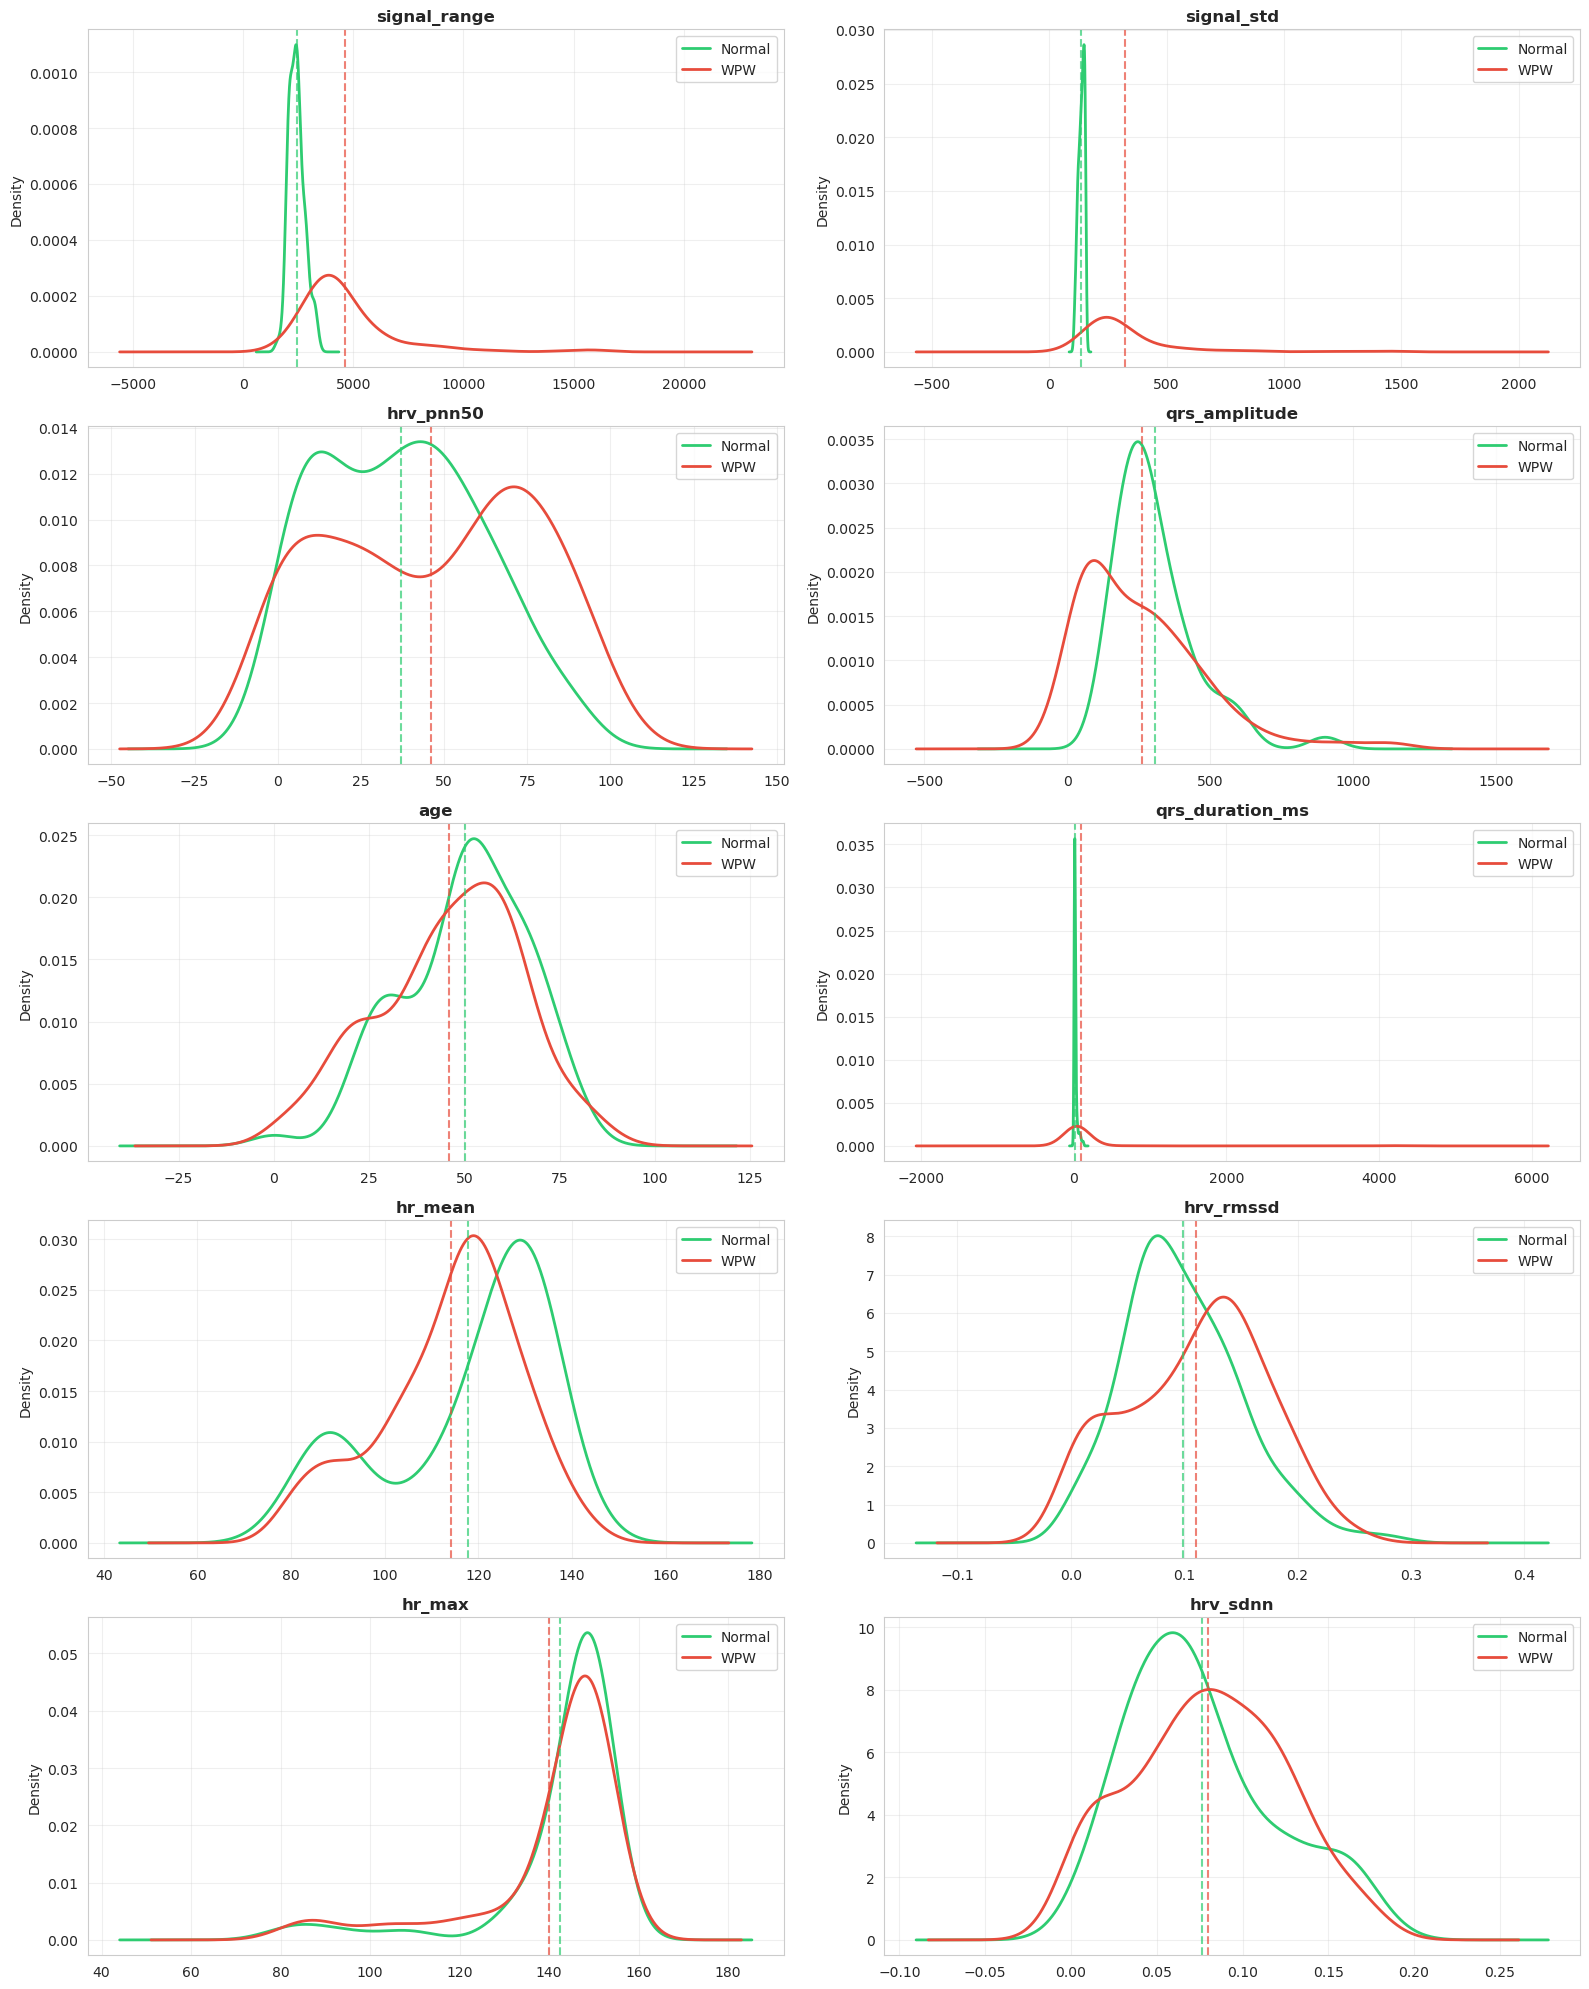


📊 SECTION 8: OUTLIER DETECTION
--------------------------------------------------------------------------------

🔹 OUTLIER COUNTS (IQR Method):
                 Outlier_Count
hr_max                      41
qrs_duration_ms             31
signal_std                  24
signal_range                16
qrs_amplitude                9
age                          2
hrv_rmssd                    1
hr_mean                      0
hr_std                       0
hrv_sdnn                     0
hrv_pnn50                    0


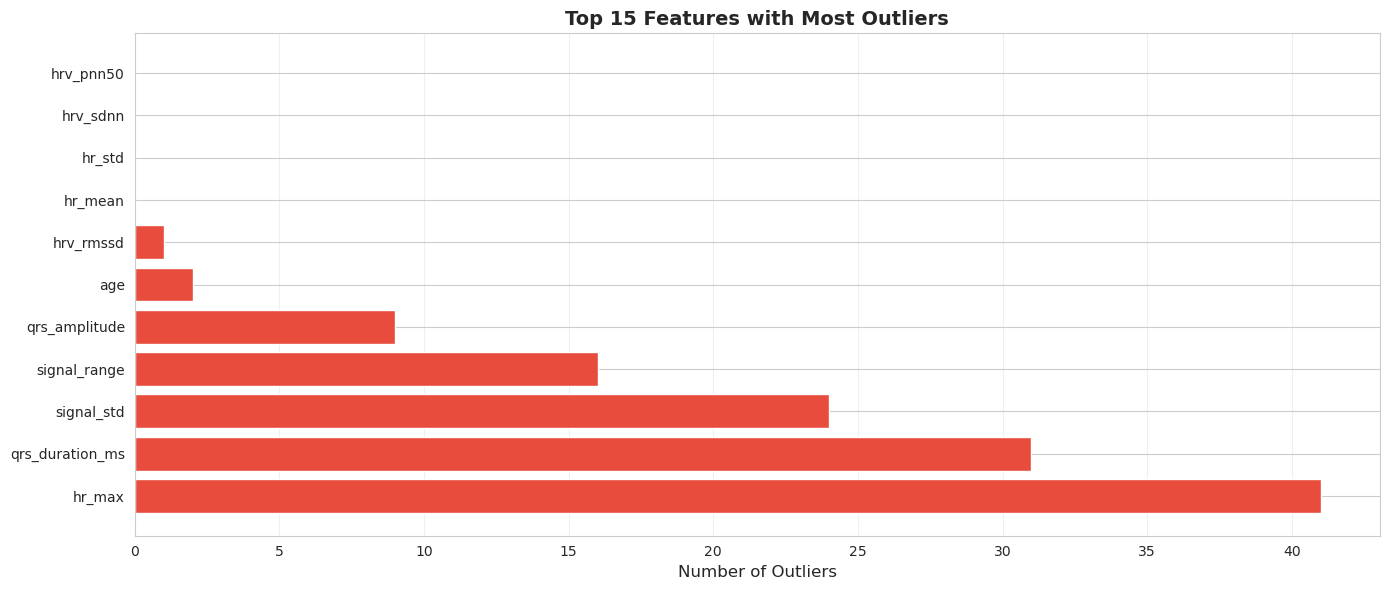


📊 EDA SUMMARY REPORT

✅ Dataset Size: 320 samples, 14 features
✅ Class Balance: 160 Normal vs 160 WPW (Ratio: 1.00:1)
✅ Missing Values: 0 features with missing data
✅ Numeric Features: 11
✅ Top Correlated Feature: signal_range (r=0.565)
✅ Most Outliers in: hr_max (41 outliers)

🎯 Key Findings:
   - Age difference: t=-2.964, p=0.0321
   - Strong correlations detected in: signal_range, signal_std, hrv_pnn50
   - HRV features: 3 available for analysis


✅ EDA Complete! Ready for feature selection and modeling.


In [19]:

print("=" * 80)
print("STEP 4: MERGING DATASETS & PREPROCESSING")
print("=" * 80)

# ===============================
# LOAD DATASETS
# ===============================
print("\n📥 Loading datasets...")

# WPW dataset (from Cell 3)
df_wpw = pd.read_csv("cleanestwpwp.csv")
print(f"   - WPW records: {len(df_wpw)}")

# Normal sinus rhythm dataset
df_normal = pd.read_csv("only_sinus_cleanest_160.csv")
print(f"   - Normal records: {len(df_normal)}")

# ===============================
# HARMONIZE COLUMNS
# ===============================
print("\n🔧 Harmonizing column names...")

# Add missing columns to WPW dataset
for col in df_normal.columns:
    if col not in df_wpw.columns:
        df_wpw[col] = np.nan

# Add missing columns to normal dataset
for col in df_wpw.columns:
    if col not in df_normal.columns:
        df_normal[col] = np.nan

# Reorder columns to match
df_normal = df_normal[df_wpw.columns]
print(f"   ✅ Column alignment complete")

# ===============================
# MERGE DATASETS
# ===============================
print("\n🔀 Merging datasets...")
df_merged = pd.concat([df_wpw, df_normal], ignore_index=True)
print(f"   ✅ Merged dataset size: {len(df_merged)} records")
print(f"   - WPW positive (dx=1): {(df_merged['dx'] == 1).sum()}")
print(f"   - Normal (dx=0): {(df_merged['dx'] == 0).sum()}")

# ===============================
# PREPROCESSING
# ===============================
print("\n🧹 Preprocessing data...")

# 1. Encode sex column
df_merged['sex'] = df_merged['sex'].replace({
    'Male': 1, 'M': 1, 'male': 1,
    'Female': 0, 'F': 0, 'female': 0
})

# 2. Fill missing numeric values with median
numeric_cols = df_merged.select_dtypes(include=np.number).columns.tolist()
df_merged[numeric_cols] = df_merged[numeric_cols].fillna(df_merged[numeric_cols].median())

# 3. Log-transform skewed HRV features
for col in ["hrv_rmssd", "hrv_sdnn"]:
    if col in df_merged.columns:
        df_merged[col] = np.log1p(df_merged[col])

print(f"   ✅ Sex encoding complete")
print(f"   ✅ Missing values filled")
print(f"   ✅ HRV features log-transformed")

# ===============================
# SAVE MERGED DATASET
# ===============================
MERGED_CSV = "merged_cleanest_ecg.csv"
df_merged.to_csv(MERGED_CSV, index=False)
print(f"\n💾 Saved merged dataset: {MERGED_CSV}")

# ===============================
# DATA SUMMARY
# ===============================
print("\n" + "=" * 80)
print("DATASET SUMMARY")
print("=" * 80)
print(f"\nShape: {df_merged.shape}")
print(f"\nClass distribution:")
print(df_merged['dx'].value_counts())
print(f"\nFeature statistics:")
print(df_merged.describe())

print("\n✅ Data preparation complete! Ready for modeling.")
print("=" * 80)


# ========================================
# CELL 5: EXPLORATORY DATA ANALYSIS (EDA)
# ========================================
print("\n" + "=" * 80)
print("COMPREHENSIVE EXPLORATORY DATA ANALYSIS")
print("=" * 80)

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (15, 10)

# ===============================
# 1. DATA OVERVIEW
# ===============================
print("\n📊 SECTION 1: DATA OVERVIEW")
print("-" * 80)

print(f"\nDataset Dimensions: {df_merged.shape[0]} rows × {df_merged.shape[1]} columns")
print(f"\nMemory Usage: {df_merged.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\nColumn Data Types:")
print(df_merged.dtypes.value_counts())

print("\nMissing Values Summary:")
missing = df_merged.isnull().sum()
missing_pct = 100 * missing / len(df_merged)
missing_df = pd.DataFrame({
    'Missing_Count': missing,
    'Percentage': missing_pct
}).sort_values('Missing_Count', ascending=False)
print(missing_df[missing_df['Missing_Count'] > 0])

# ===============================
# 2. TARGET VARIABLE ANALYSIS
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 2: TARGET VARIABLE ANALYSIS (dx)")
print("-" * 80)

# Class distribution
class_counts = df_merged['dx'].value_counts()
class_pct = 100 * class_counts / len(df_merged)

print("\nClass Distribution:")
print(f"   Normal (dx=0): {class_counts[0]} ({class_pct[0]:.2f}%)")
print(f"   WPW (dx=1): {class_counts[1]} ({class_pct[1]:.2f}%)")
print(f"\nImbalance Ratio: {class_counts[0] / class_counts[1]:.2f}:1")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
sns.countplot(data=df_merged, x='dx', ax=axes[0], palette=['#2ecc71', '#e74c3c'])
axes[0].set_title('Class Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Diagnosis (0=Normal, 1=WPW)', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
for i, (count, pct) in enumerate(zip(class_counts, class_pct)):
    axes[0].text(i, count + 5, f'{count}\n({pct:.1f}%)', 
                 ha='center', fontsize=11, fontweight='bold')

# Pie chart
axes[1].pie(class_counts, labels=['Normal', 'WPW'], autopct='%1.1f%%',
            colors=['#2ecc71', '#e74c3c'], startangle=90)
axes[1].set_title('Class Proportion', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# ===============================
# 3. DEMOGRAPHIC ANALYSIS
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 3: DEMOGRAPHIC FEATURES")
print("-" * 80)

# Age analysis
print("\n🔹 AGE DISTRIBUTION:")
print(df_merged.groupby('dx')['age'].describe())

# Sex distribution
print("\n🔹 SEX DISTRIBUTION:")
sex_dx = pd.crosstab(df_merged['dx'], df_merged['sex'], normalize='index') * 100
print(sex_dx)

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Age distribution by diagnosis
axes[0, 0].hist([df_merged[df_merged['dx']==0]['age'], 
                 df_merged[df_merged['dx']==1]['age']], 
                label=['Normal', 'WPW'], bins=30, alpha=0.7, color=['#2ecc71', '#e74c3c'])
axes[0, 0].set_title('Age Distribution by Diagnosis', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Age (years)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Box plot: Age by diagnosis
sns.boxplot(data=df_merged, x='dx', y='age', ax=axes[0, 1], 
            palette=['#2ecc71', '#e74c3c'])
axes[0, 1].set_title('Age Distribution by Diagnosis (Boxplot)', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Diagnosis (0=Normal, 1=WPW)')
axes[0, 1].set_ylabel('Age (years)')

# Sex distribution by diagnosis
sex_counts = df_merged.groupby(['dx', 'sex']).size().unstack()
sex_counts.plot(kind='bar', ax=axes[1, 0], color=['#f39c12', '#9b59b6'], alpha=0.8)
axes[1, 0].set_title('Sex Distribution by Diagnosis', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Diagnosis (0=Normal, 1=WPW)')
axes[1, 0].set_ylabel('Count')
axes[1, 0].legend(['Female', 'Male'])
axes[1, 0].set_xticklabels(['Normal', 'WPW'], rotation=0)

# Age vs Sex interaction
sns.violinplot(data=df_merged, x='dx', y='age', hue='sex', 
               ax=axes[1, 1], palette=['#f39c12', '#9b59b6'], split=True)
axes[1, 1].set_title('Age Distribution by Diagnosis & Sex', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Diagnosis (0=Normal, 1=WPW)')
axes[1, 1].set_ylabel('Age (years)')
axes[1, 1].legend(title='Sex', labels=['Female', 'Male'])

plt.tight_layout()
plt.show()

# Statistical test: Age difference
normal_age = df_merged[df_merged['dx']==0]['age']
wpw_age = df_merged[df_merged['dx']==1]['age']
t_stat, p_value = stats.ttest_ind(normal_age, wpw_age)
print(f"\n📈 T-test for age difference: t={t_stat:.3f}, p={p_value:.4f}")

# ===============================
# 4. HEART RATE ANALYSIS
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 4: HEART RATE METRICS")
print("-" * 80)

hr_features = ['heart_rate', 'rr_mean', 'rr_std']
available_hr = [f for f in hr_features if f in df_merged.columns]

if available_hr:
    print("\n🔹 HEART RATE STATISTICS BY DIAGNOSIS:")
    print(df_merged.groupby('dx')[available_hr].describe())
    
    # Visualization
    n_features = len(available_hr)
    fig, axes = plt.subplots(1, n_features, figsize=(6*n_features, 5))
    if n_features == 1:
        axes = [axes]
    
    for i, feature in enumerate(available_hr):
        sns.boxplot(data=df_merged, x='dx', y=feature, ax=axes[i],
                    palette=['#2ecc71', '#e74c3c'])
        axes[i].set_title(f'{feature.upper()} by Diagnosis', fontsize=12, fontweight='bold')
        axes[i].set_xlabel('Diagnosis (0=Normal, 1=WPW)')
        
        # Add statistical test
        normal_vals = df_merged[df_merged['dx']==0][feature]
        wpw_vals = df_merged[df_merged['dx']==1][feature]
        t_stat, p_val = stats.ttest_ind(normal_vals, wpw_vals, nan_policy='omit')
        axes[i].text(0.5, axes[i].get_ylim()[1]*0.95, f'p={p_val:.4f}',
                     ha='center', fontsize=10, bbox=dict(boxstyle='round', facecolor='wheat'))
    
    plt.tight_layout()
    plt.show()

# ===============================
# 5. HRV FEATURES ANALYSIS
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 5: HEART RATE VARIABILITY (HRV)")
print("-" * 80)

hrv_features = [col for col in df_merged.columns if 'hrv' in col.lower()]

if hrv_features:
    print(f"\n🔹 Found {len(hrv_features)} HRV features:")
    print(hrv_features)
    
    print("\n🔹 HRV STATISTICS BY DIAGNOSIS:")
    print(df_merged.groupby('dx')[hrv_features].describe())
    
    # Visualization
    n_rows = (len(hrv_features) + 2) // 3
    fig, axes = plt.subplots(n_rows, 3, figsize=(18, 5*n_rows))
    axes = axes.flatten()
    
    for i, feature in enumerate(hrv_features):
        sns.boxplot(data=df_merged, x='dx', y=feature, ax=axes[i],
                    palette=['#2ecc71', '#e74c3c'])
        axes[i].set_title(f'{feature.upper()}', fontsize=11, fontweight='bold')
        axes[i].set_xlabel('Diagnosis (0=Normal, 1=WPW)')
        
        # Statistical test
        normal_vals = df_merged[df_merged['dx']==0][feature].dropna()
        wpw_vals = df_merged[df_merged['dx']==1][feature].dropna()
        if len(normal_vals) > 0 and len(wpw_vals) > 0:
            t_stat, p_val = stats.ttest_ind(normal_vals, wpw_vals)
            axes[i].text(0.5, axes[i].get_ylim()[1]*0.95, f'p={p_val:.4f}',
                         ha='center', fontsize=9, bbox=dict(boxstyle='round', facecolor='lightblue'))
    
    # Hide extra subplots
    for j in range(len(hrv_features), len(axes)):
        axes[j].axis('off')
    
    plt.tight_layout()
    plt.show()

# ===============================
# 6. CORRELATION ANALYSIS
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 6: FEATURE CORRELATION ANALYSIS")
print("-" * 80)

# Select numeric features
numeric_features = df_merged.select_dtypes(include=[np.number]).columns.tolist()
if 'dx' in numeric_features:
    numeric_features.remove('dx')

# Compute correlation with target
correlations = df_merged[numeric_features + ['dx']].corr()['dx'].drop('dx').sort_values(ascending=False)
print("\n🔹 TOP 15 FEATURES CORRELATED WITH DIAGNOSIS:")
print(correlations.head(15))

print("\n🔹 BOTTOM 15 FEATURES CORRELATED WITH DIAGNOSIS:")
print(correlations.tail(15))

# Visualization: Correlation heatmap
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Full correlation matrix (top 20 features)
top_features = correlations.abs().nlargest(20).index.tolist()
corr_matrix = df_merged[top_features + ['dx']].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            ax=axes[0], cbar_kws={'label': 'Correlation'})
axes[0].set_title('Correlation Matrix: Top 20 Features', fontsize=14, fontweight='bold')

# Correlation with target
corr_with_target = correlations.nlargest(20)
colors = ['#e74c3c' if x > 0 else '#3498db' for x in corr_with_target]
axes[1].barh(range(len(corr_with_target)), corr_with_target.values, color=colors)
axes[1].set_yticks(range(len(corr_with_target)))
axes[1].set_yticklabels(corr_with_target.index, fontsize=9)
axes[1].set_xlabel('Correlation with Diagnosis', fontsize=12)
axes[1].set_title('Top 20 Features Correlated with WPW', fontsize=14, fontweight='bold')
axes[1].axvline(x=0, color='black', linestyle='--', linewidth=0.8)
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# ===============================
# 7. FEATURE DISTRIBUTIONS
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 7: FEATURE DISTRIBUTION ANALYSIS")
print("-" * 80)

# Select top features for distribution analysis
top_10_features = correlations.abs().nlargest(10).index.tolist()

print(f"\n🔹 Analyzing distributions for top 10 correlated features:")
print(top_10_features)

# Plot distributions
fig, axes = plt.subplots(5, 2, figsize=(16, 20))
axes = axes.flatten()

for i, feature in enumerate(top_10_features):
    # KDE plot
    df_merged[df_merged['dx']==0][feature].plot(kind='kde', ax=axes[i], 
                                                  label='Normal', color='#2ecc71', linewidth=2)
    df_merged[df_merged['dx']==1][feature].plot(kind='kde', ax=axes[i], 
                                                  label='WPW', color='#e74c3c', linewidth=2)
    axes[i].set_title(f'{feature}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].legend()
    axes[i].grid(alpha=0.3)
    
    # Add mean lines
    mean_normal = df_merged[df_merged['dx']==0][feature].mean()
    mean_wpw = df_merged[df_merged['dx']==1][feature].mean()
    axes[i].axvline(mean_normal, color='#2ecc71', linestyle='--', alpha=0.7, linewidth=1.5)
    axes[i].axvline(mean_wpw, color='#e74c3c', linestyle='--', alpha=0.7, linewidth=1.5)

plt.tight_layout()
plt.show()

# ===============================
# 8. OUTLIER DETECTION
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 8: OUTLIER DETECTION")
print("-" * 80)

# Calculate outliers using IQR method
outlier_counts = {}
for col in numeric_features[:15]:  # Check top 15 numeric features
    Q1 = df_merged[col].quantile(0.25)
    Q3 = df_merged[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df_merged[col] < (Q1 - 1.5 * IQR)) | (df_merged[col] > (Q3 + 1.5 * IQR))).sum()
    outlier_counts[col] = outliers

outlier_df = pd.DataFrame.from_dict(outlier_counts, orient='index', 
                                     columns=['Outlier_Count']).sort_values('Outlier_Count', ascending=False)
print("\n🔹 OUTLIER COUNTS (IQR Method):")
print(outlier_df.head(15))

# Visualization
fig, ax = plt.subplots(figsize=(14, 6))
top_outliers = outlier_df.head(15)
ax.barh(range(len(top_outliers)), top_outliers['Outlier_Count'].values, color='#e74c3c')
ax.set_yticks(range(len(top_outliers)))
ax.set_yticklabels(top_outliers.index, fontsize=10)
ax.set_xlabel('Number of Outliers', fontsize=12)
ax.set_title('Top 15 Features with Most Outliers', fontsize=14, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# ===============================
# 9. SUMMARY REPORT
# ===============================
print("\n" + "=" * 80)
print("📊 EDA SUMMARY REPORT")
print("=" * 80)

print(f"""
✅ Dataset Size: {df_merged.shape[0]} samples, {df_merged.shape[1]} features
✅ Class Balance: {class_counts[0]} Normal vs {class_counts[1]} WPW (Ratio: {class_counts[0]/class_counts[1]:.2f}:1)
✅ Missing Values: {missing[missing > 0].shape[0]} features with missing data
✅ Numeric Features: {len(numeric_features)}
✅ Top Correlated Feature: {correlations.abs().idxmax()} (r={correlations.abs().max():.3f})
✅ Most Outliers in: {outlier_df.index[0]} ({outlier_df.iloc[0, 0]} outliers)

🎯 Key Findings:
   - Age difference: t={t_stat:.3f}, p={p_value:.4f}
   - Strong correlations detected in: {', '.join(correlations.abs().nlargest(3).index.tolist())}
   - HRV features: {len(hrv_features)} available for analysis
""")

print("\n✅ EDA Complete! Ready for feature selection and modeling.")
print("=" * 80)

## ========================================
###  MODEL TRAINING & EVALUATION
## ========================================
### Purpose: Train logistic regression model with hyperparameter tuning

STEP 5: MODEL TRAINING & EVALUATION

📥 Loading merged dataset...
   - Total records: 320
   - WPW positive: 160
   - Normal: 160

🎯 Preparing features and target...
   ✅ Features shape: (320, 12)
   ✅ Target shape: (320,)

📊 Splitting data (80% train, 20% test)...
   - Training set: 256 samples
   - Test set: 64 samples

🔧 Building ML pipeline...
   ✅ Pipeline: Scaling → Polynomial Features → Logistic Regression

⚙️ Performing hyperparameter tuning (Grid Search)...
Fitting 5 folds for each of 40 candidates, totalling 200 fits

BEST HYPERPARAMETERS
   logreg__C: 1
   logreg__penalty: l1
   poly__degree: 1
   poly__interaction_only: False

CROSS-VALIDATION RESULTS (5-Fold)

📊 AUC-ROC Scores: ['0.9697', '0.9766', '0.9834', '0.9629', '0.9648']
   Mean AUC-ROC: 0.9715 ± 0.0076

📊 Accuracy Scores: ['0.9375', '0.9219', '0.9531', '0.9531', '0.9531']
   Mean Accuracy: 0.9437 ± 0.0125

TEST SET PERFORMANCE

✅ Accuracy: 0.9688
✅ AUC-ROC: 0.9775

📊 Confusion Matrix:
   [[32  0]
 [ 2 30]]

   TN: 3

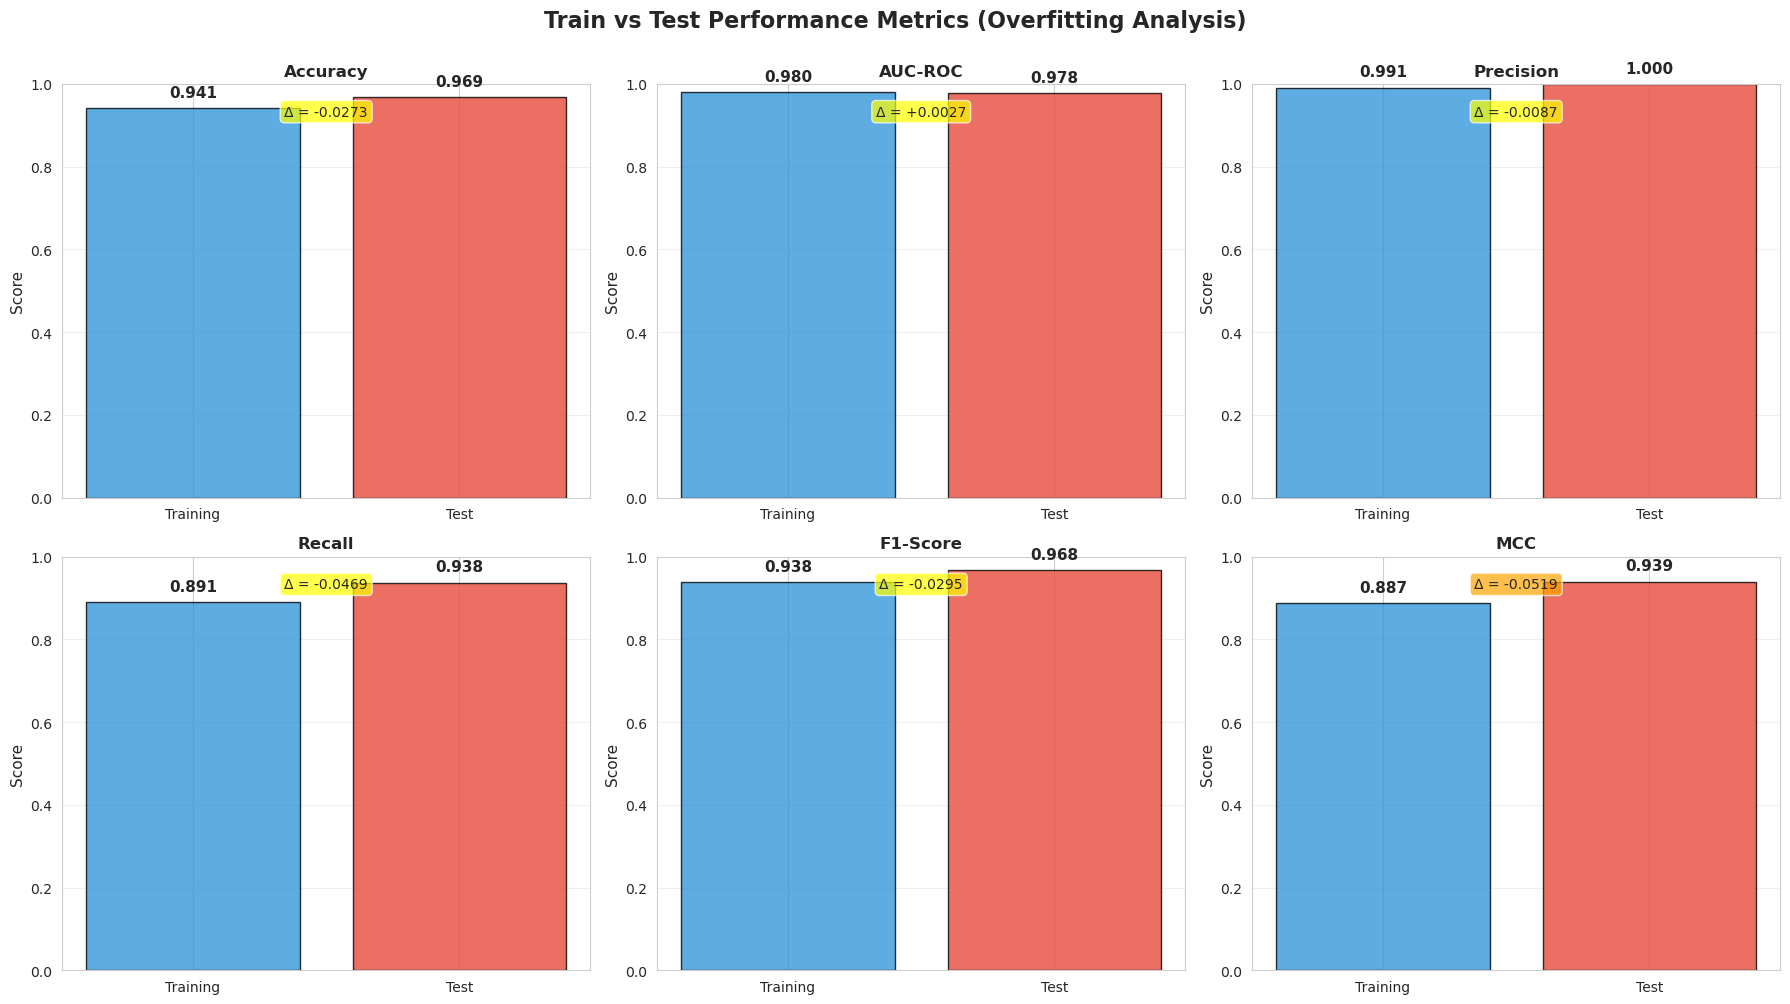


📊 SECTION 2: ROC CURVE ANALYSIS
--------------------------------------------------------------------------------


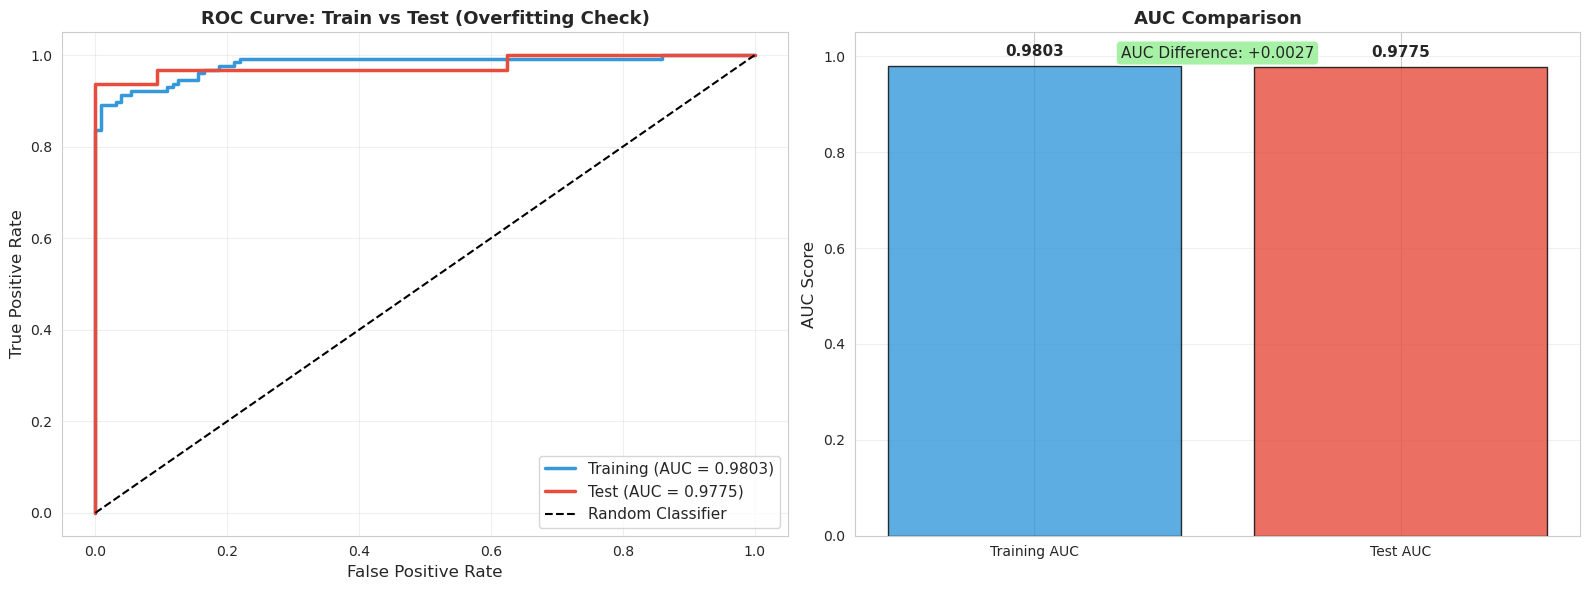


   Training AUC: 0.9803
   Test AUC: 0.9775
   AUC Difference: +0.0027

📊 SECTION 3: PRECISION-RECALL ANALYSIS
--------------------------------------------------------------------------------


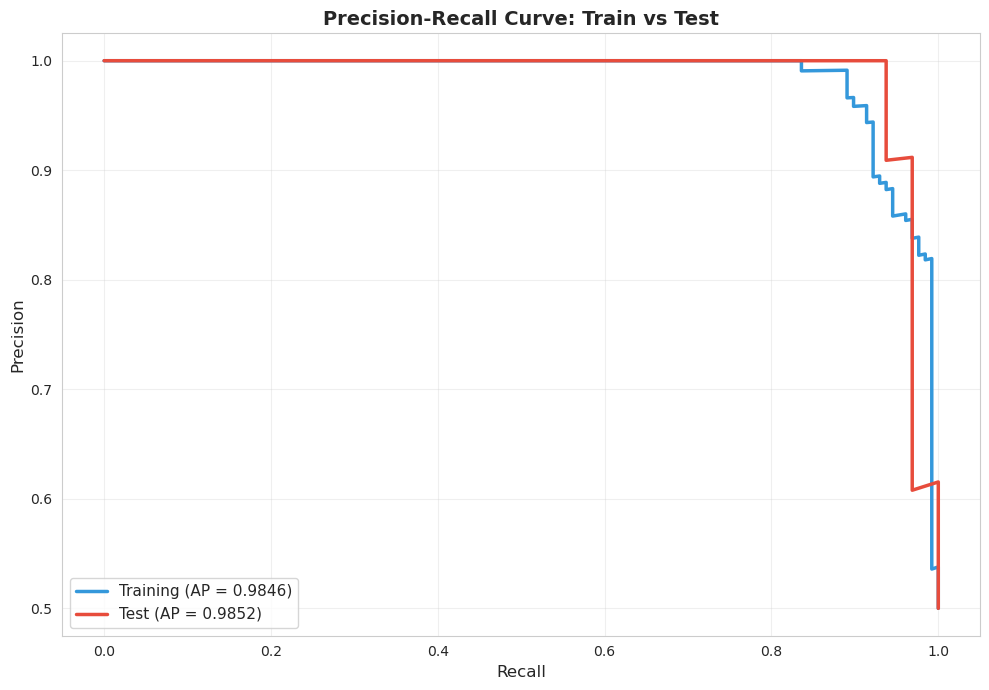


   Training AP: 0.9846
   Test AP: 0.9852
   AP Difference: -0.0006

📊 SECTION 4: LEARNING CURVES (Overfitting Detection)
--------------------------------------------------------------------------------


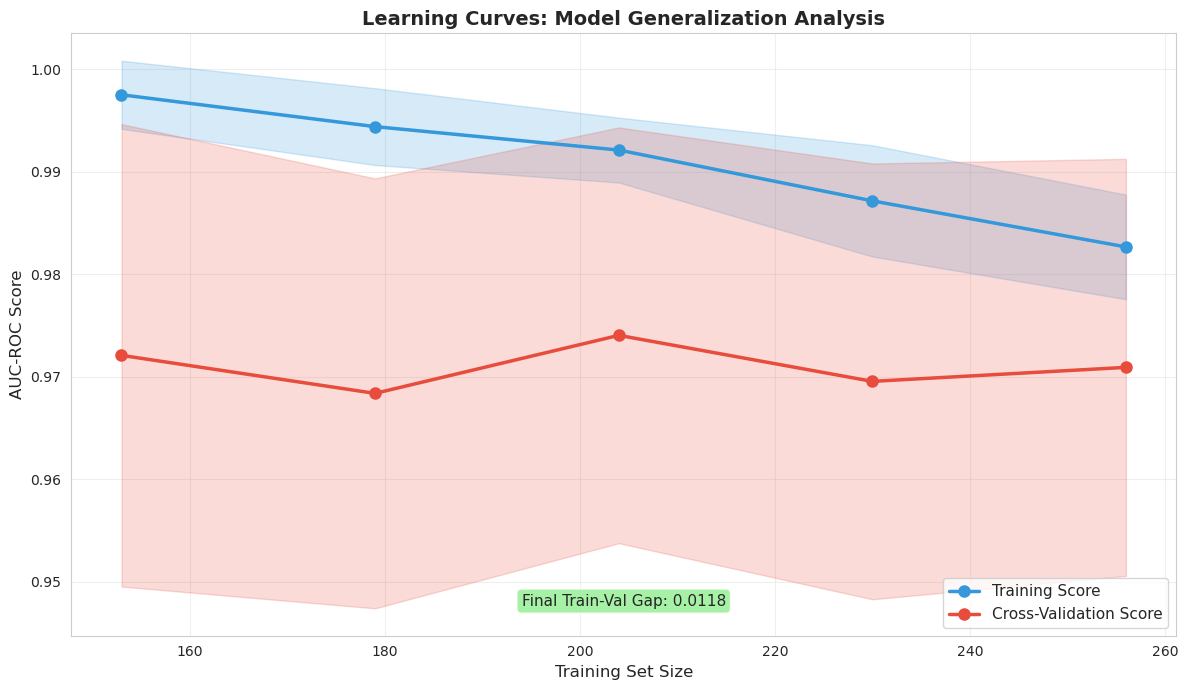


   Training score at max size: 0.9827 ± 0.0051
   Validation score at max size: 0.9709 ± 0.0203
   Train-Val gap: 0.0118
   ✅ EXCELLENT: Learning curves converge well - No overfitting!

📊 SECTION 5: CONFUSION MATRIX VISUALIZATION
--------------------------------------------------------------------------------


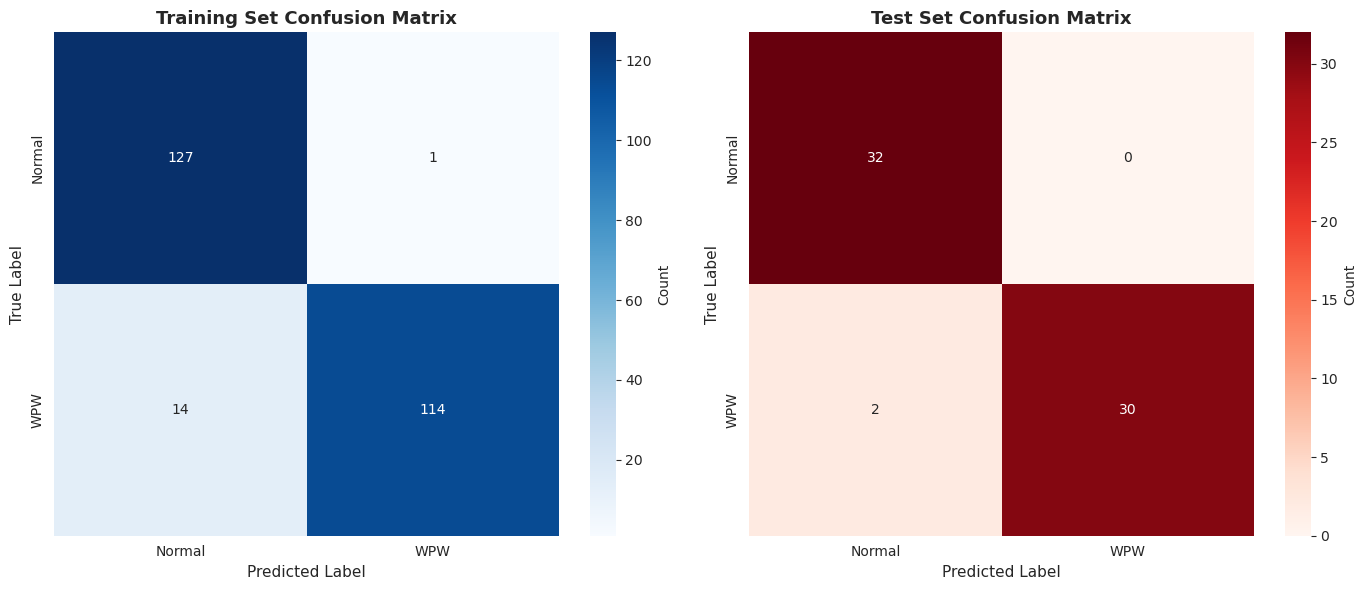


📊 SECTION 6: VALIDATION CURVE (Regularization Analysis)
--------------------------------------------------------------------------------


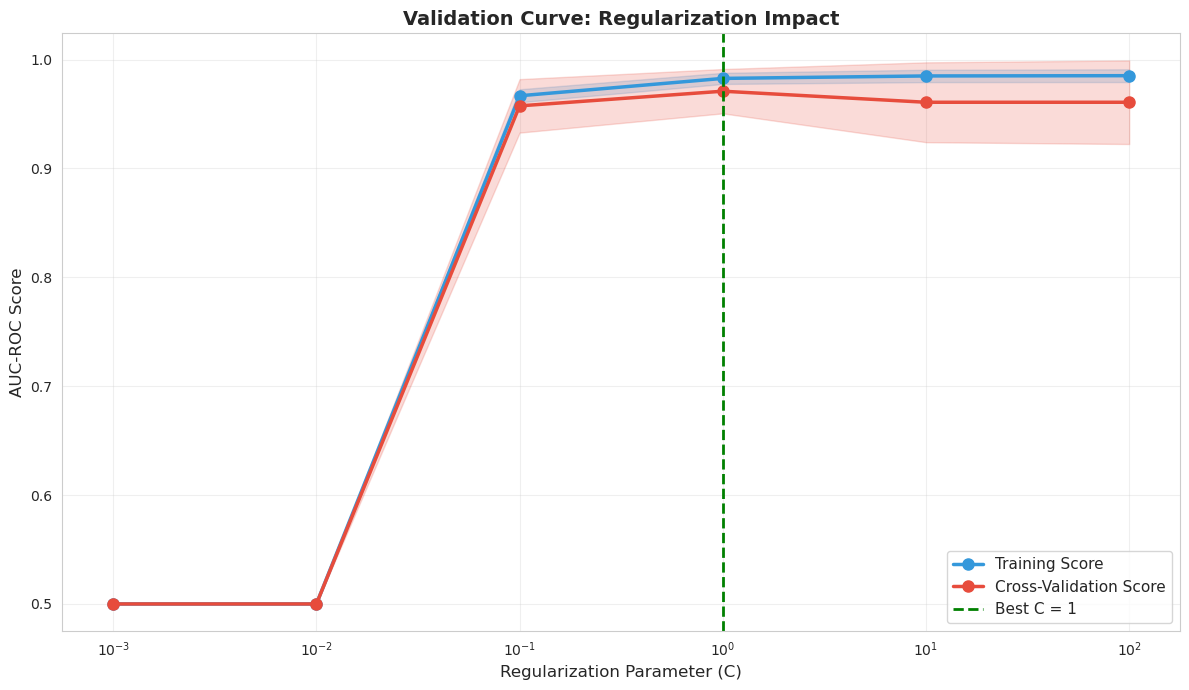


📊 SECTION 7: CROSS-VALIDATION CONSISTENCY
--------------------------------------------------------------------------------


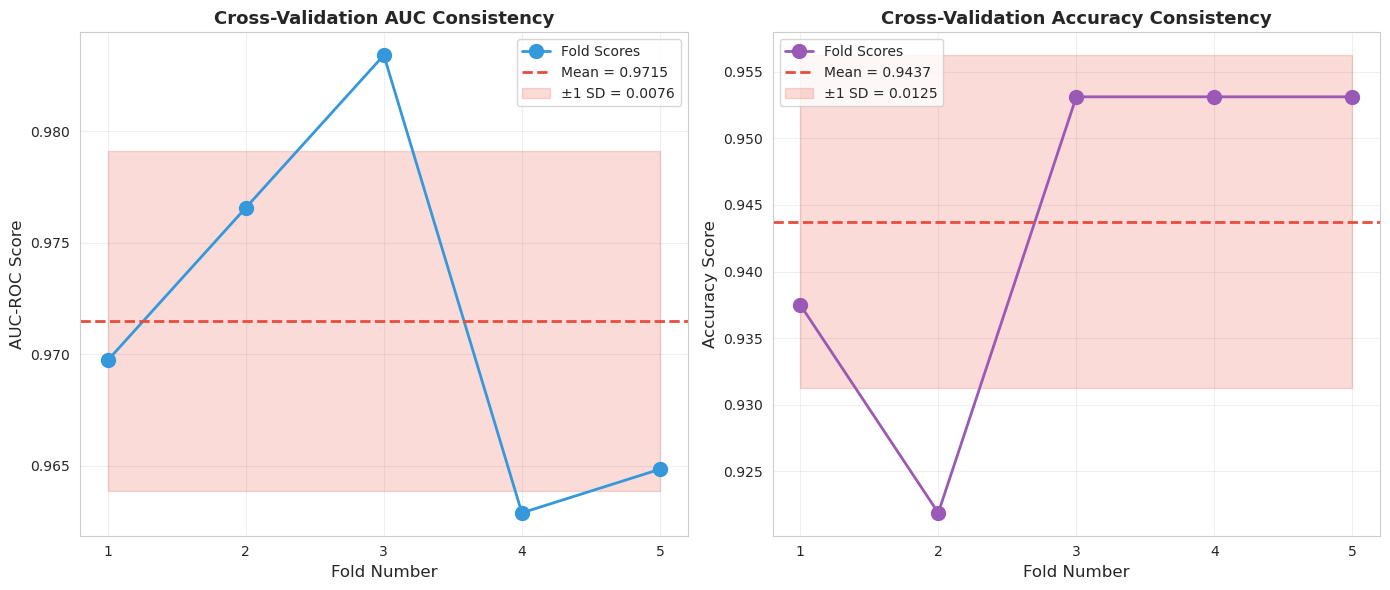


   AUC Coefficient of Variation: 0.78%
   Accuracy Coefficient of Variation: 1.32%

🎯 FINAL OVERFITTING ASSESSMENT

📊 Overfitting Indicators:
   Train-Test Accuracy Gap       : 0.0273  ✅ Good
   Train-Test AUC Gap            : 0.0027  ✅ Good
   Train-Test F1 Gap             : 0.0295  ✅ Good
   Learning Curve Gap            : 0.0118  ✅ Good
   CV Standard Deviation (AUC)   : 0.0076  ✅ Good

📈 Average Overfitting Score: 0.0158

🎉 EXCELLENT MODEL GENERALIZATION!
   ✅ No significant overfitting detected
   ✅ Model performs consistently on train and test data
   ✅ Ready for deployment

✅ COMPREHENSIVE EVALUATION COMPLETE!

BOOTSTRAP RESAMPLING ANALYSIS

💡 Note: While CV shows excellent stability (low variance),
   bootstrapping provides formal confidence intervals for all metrics.

📊 SECTION 1: BOOTSTRAP SETUP
--------------------------------------------------------------------------------

⚙️ Configuration:
   - Bootstrap iterations: 1000
   - Confidence level: 95%
   - Random seed: 42

⏳

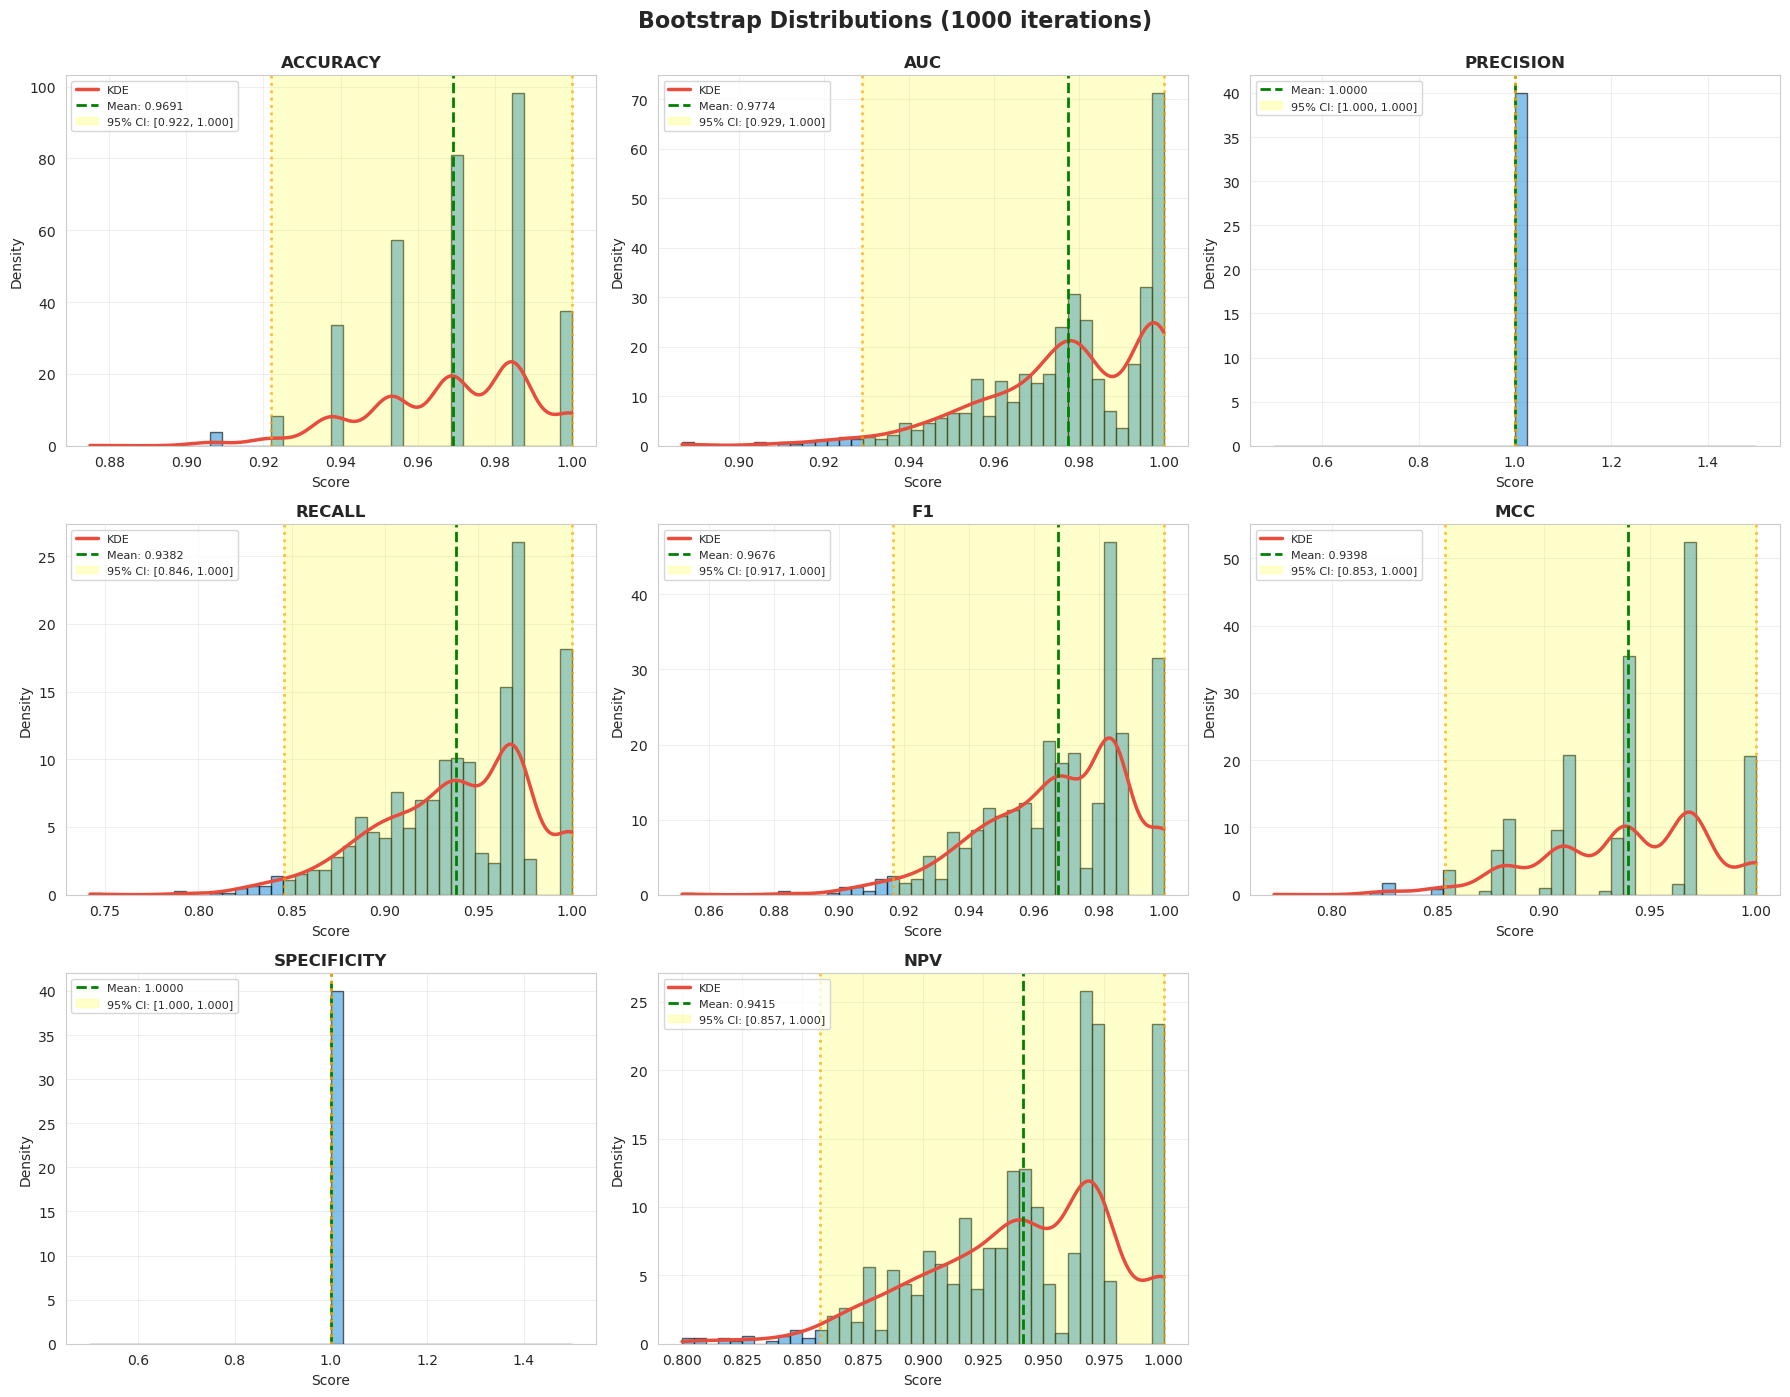


📊 SECTION 4: BOOTSTRAP vs ORIGINAL TEST METRICS
--------------------------------------------------------------------------------

🔍 Comparison: Original Test vs Bootstrap Mean:
   Metric  Original Test  Bootstrap Mean  Difference Within CI?
 ACCURACY         0.9688          0.9691      0.0003      ✅ Yes
      AUC         0.9775          0.9774     -0.0002      ✅ Yes
PRECISION         1.0000          1.0000      0.0000      ✅ Yes
   RECALL         0.9375          0.9382      0.0007      ✅ Yes
       F1         0.9677          0.9676     -0.0001      ✅ Yes
      MCC         0.9393          0.9398      0.0005      ✅ Yes


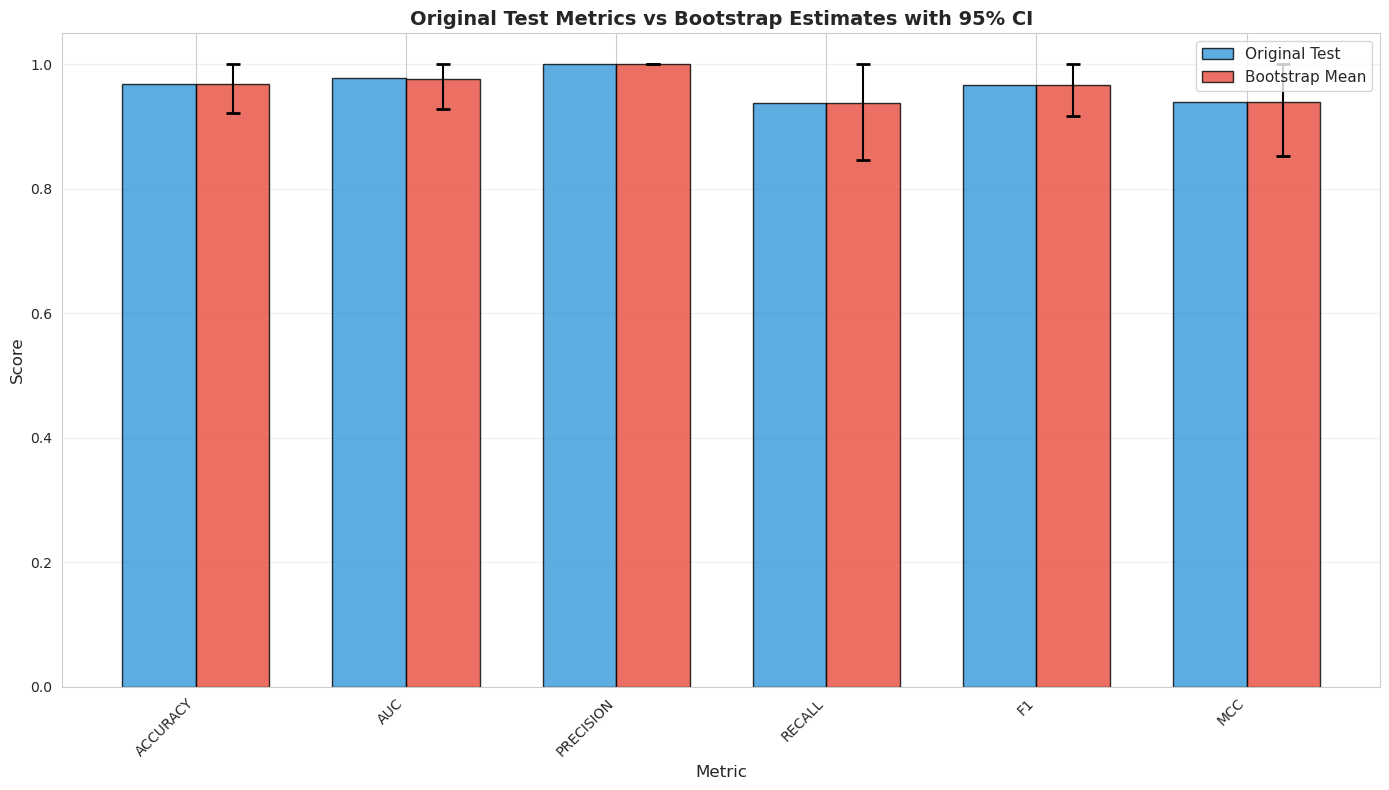


📊 SECTION 5: FEATURE COEFFICIENT STABILITY
--------------------------------------------------------------------------------

⏳ Bootstrapping feature coefficients...
   ✅ Coefficient bootstrapping complete!

🎯 TOP 20 STABLE FEATURES (CI doesn't cross zero):
   feature  mean_coef    std  ci_lower  ci_upper
signal_std     8.4168 1.6703    5.2356   11.5720
       sex     0.8542 0.2681    0.2991    1.3805
       age    -0.6890 0.2840   -1.2350   -0.1179


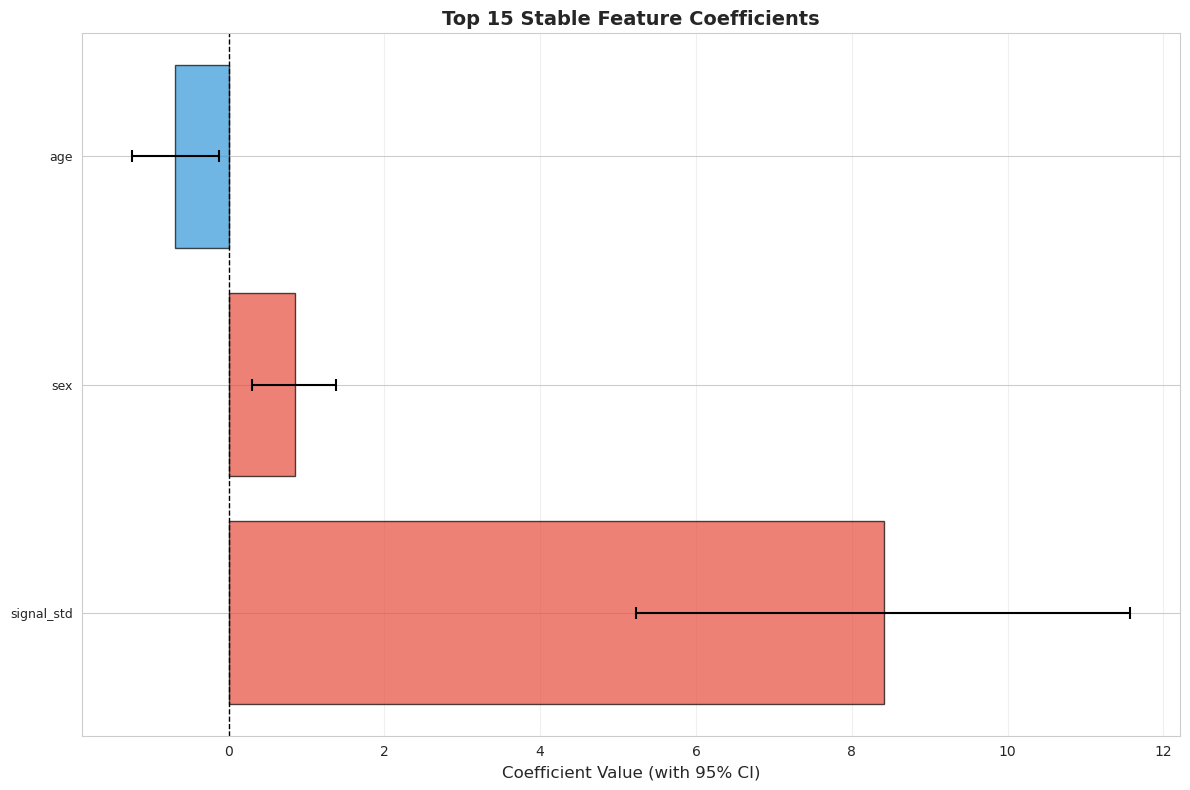


📊 SECTION 6: PREDICTION STABILITY ANALYSIS
--------------------------------------------------------------------------------

📊 Prediction Agreement Across Bootstrap Samples:
   Mean Agreement: 0.5091
   Std Dev: 0.0686
   ⚠️ WARNING: Predictions show some instability

🎯 BOOTSTRAP ANALYSIS SUMMARY

📊 BOOTSTRAP RESULTS (1000 iterations):

✅ Performance Metrics:
   - AUC: 0.9774 [0.9291, 1.0000]
   - Accuracy: 0.9691 [0.9219, 1.0000]
   - F1-Score: 0.9676 [0.9166, 1.0000]
   - MCC: 0.9398 [0.8534, 1.0000]

✅ Stability Assessment:
   - Average CI Width: 0.0845 (Good)
   - Prediction Stability: 0.5091 (Moderate)
   - Stable Features Found: 3 features with CI not crossing zero

✅ Validation:
   - Original test metrics all fall within bootstrap CIs: True
   - Bootstrap confirms: Good generalization

💡 CONCLUSION:
   ✅ Your model shows good stability and can be trusted for deployment.
   Bootstrap analysis confirms the cross-validation results.
   Confidence intervals are narrow, indicating r

In [20]:


from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report

print("=" * 80)
print("STEP 5: MODEL TRAINING & EVALUATION")
print("=" * 80)

# ===============================
# LOAD PREPARED DATA
# ===============================
print("\n📥 Loading merged dataset...")

df = pd.read_csv("merged_cleanest_ecg.csv")
print(f"   - Total records: {len(df)}")
print(f"   - WPW positive: {(df['dx'] == 1).sum()}")
print(f"   - Normal: {(df['dx'] == 0).sum()}")

# ===============================
# PREPARE FEATURES & TARGET
# ===============================
print("\n🎯 Preparing features and target...")

# Drop non-feature columns
X = df.drop(columns=["dx", "record_id"])
y = df["dx"]

# Ensure all features are numeric
X = X.apply(pd.to_numeric, errors="coerce")
X = X.fillna(X.median())

print(f"   ✅ Features shape: {X.shape}")
print(f"   ✅ Target shape: {y.shape}")

# ===============================
# TRAIN-TEST SPLIT
# ===============================
print("\n📊 Splitting data (80% train, 20% test)...")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f"   - Training set: {len(X_train)} samples")
print(f"   - Test set: {len(X_test)} samples")

# ===============================
# BUILD PIPELINE
# ===============================
print("\n🔧 Building ML pipeline...")

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("logreg", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    ))
])

print("   ✅ Pipeline: Scaling → Polynomial Features → Logistic Regression")

# ===============================
# HYPERPARAMETER TUNING
# ===============================
print("\n⚙️ Performing hyperparameter tuning (Grid Search)...")

param_grid = {
    "poly__degree": [1, 2],
    "poly__interaction_only": [False, True],
    "logreg__penalty": ["l1", "l2"],
    "logreg__C": [0.001, 0.01, 0.1, 1, 10]
}

grid_search = GridSearchCV(
    pipe,
    param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

print("\n" + "=" * 80)
print("BEST HYPERPARAMETERS")
print("=" * 80)
for param, value in grid_search.best_params_.items():
    print(f"   {param}: {value}")

# ===============================
# CROSS-VALIDATION
# ===============================
print("\n" + "=" * 80)
print("CROSS-VALIDATION RESULTS (5-Fold)")
print("=" * 80)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_auc = cross_val_score(best_model, X, y, cv=cv, scoring="roc_auc")
cv_acc = cross_val_score(best_model, X, y, cv=cv, scoring="accuracy")

print(f"\n📊 AUC-ROC Scores: {[f'{score:.4f}' for score in cv_auc]}")
print(f"   Mean AUC-ROC: {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")

print(f"\n📊 Accuracy Scores: {[f'{score:.4f}' for score in cv_acc]}")
print(f"   Mean Accuracy: {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")

# ===============================
# TEST SET EVALUATION
# ===============================
print("\n" + "=" * 80)
print("TEST SET PERFORMANCE")
print("=" * 80)

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

test_acc = accuracy_score(y_test, y_pred)
test_auc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)

print(f"\n✅ Accuracy: {test_acc:.4f}")
print(f"✅ AUC-ROC: {test_auc:.4f}")

print(f"\n📊 Confusion Matrix:")
print(f"   {cm}")
print(f"\n   TN: {cm[0,0]}  |  FP: {cm[0,1]}")
print(f"   FN: {cm[1,0]}  |  TP: {cm[1,1]}")

print(f"\n📋 Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Normal', 'WPW']))

# ===============================
# FEATURE IMPORTANCE
# ===============================
print("\n" + "=" * 80)
print("TOP FEATURE IMPORTANCES (Coefficients)")
print("=" * 80)

logreg = best_model.named_steps["logreg"]
poly = best_model.named_steps["poly"]

feature_names = poly.get_feature_names_out(X.columns)
coef = pd.Series(logreg.coef_[0], index=feature_names).sort_values(ascending=False)

print(f"\n🔝 Top 10 Positive Features (WPW indicators):")
for i, (feat, val) in enumerate(coef.head(10).items(), 1):
    print(f"   {i:2d}. {feat:40s} → {val:+.4f}")

print(f"\n🔝 Top 10 Negative Features (Normal indicators):")
for i, (feat, val) in enumerate(coef.tail(10).items(), 1):
    print(f"   {i:2d}. {feat:40s} → {val:+.4f}")

print("\n" + "=" * 80)
print("✅ MODEL TRAINING COMPLETE!")
print("=" * 80)


# ========================================
# CELL 6: ADVANCED METRICS & VISUALIZATIONS
# ========================================
# Purpose: Comprehensive model evaluation with overfitting detection

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    roc_curve, auc, precision_recall_curve, average_precision_score,
    f1_score, precision_score, recall_score, matthews_corrcoef
)
from sklearn.model_selection import learning_curve, validation_curve
import numpy as np

print("\n" + "=" * 80)
print("ADVANCED MODEL EVALUATION & OVERFITTING ANALYSIS")
print("=" * 80)

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (16, 12)

# ===============================
# 1. COMPREHENSIVE METRICS
# ===============================
print("\n📊 SECTION 1: COMPREHENSIVE PERFORMANCE METRICS")
print("-" * 80)

# Calculate additional metrics
y_train_pred = best_model.predict(X_train)
y_train_prob = best_model.predict_proba(X_train)[:, 1]

# Training metrics
train_acc = accuracy_score(y_train, y_train_pred)
train_auc = roc_auc_score(y_train, y_train_prob)
train_f1 = f1_score(y_train, y_train_pred)
train_precision = precision_score(y_train, y_train_pred)
train_recall = recall_score(y_train, y_train_pred)
train_mcc = matthews_corrcoef(y_train, y_train_pred)

# Test metrics
test_f1 = f1_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred)
test_recall = recall_score(y_test, y_pred)
test_mcc = matthews_corrcoef(y_test, y_pred)

# Create comparison table
metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'AUC-ROC', 'Precision', 'Recall', 'F1-Score', 'MCC'],
    'Training': [train_acc, train_auc, train_precision, train_recall, train_f1, train_mcc],
    'Test': [test_acc, test_auc, test_precision, test_recall, test_f1, test_mcc],
    'Difference': [train_acc-test_acc, train_auc-test_auc, train_precision-test_precision, 
                   train_recall-test_recall, train_f1-test_f1, train_mcc-test_mcc]
})

print("\n🎯 TRAIN vs TEST METRICS (Overfitting Check):")
print(metrics_df.to_string(index=False))

# Overfitting assessment
avg_diff = abs(metrics_df['Difference'].mean())
print(f"\n📈 Average Train-Test Difference: {avg_diff:.4f}")
if avg_diff < 0.05:
    print("   ✅ EXCELLENT: No significant overfitting detected!")
elif avg_diff < 0.10:
    print("   ⚠️  GOOD: Minimal overfitting detected")
else:
    print("   ❌ WARNING: Potential overfitting detected")

# Visualization: Train vs Test Metrics
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Train vs Test Performance Metrics (Overfitting Analysis)', 
             fontsize=16, fontweight='bold', y=1.00)

metrics_to_plot = ['Accuracy', 'AUC-ROC', 'Precision', 'Recall', 'F1-Score', 'MCC']
colors = ['#3498db', '#e74c3c']

for idx, (ax, metric) in enumerate(zip(axes.flatten(), metrics_to_plot)):
    train_val = metrics_df[metrics_df['Metric']==metric]['Training'].values[0]
    test_val = metrics_df[metrics_df['Metric']==metric]['Test'].values[0]
    
    bars = ax.bar(['Training', 'Test'], [train_val, test_val], color=colors, alpha=0.8, edgecolor='black')
    ax.set_ylabel('Score', fontsize=11)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_ylim(0, 1.0)
    ax.grid(axis='y', alpha=0.3)
    
    # Add value labels
    for bar, val in zip(bars, [train_val, test_val]):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{val:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    # Add difference
    diff = train_val - test_val
    ax.text(0.5, 0.95, f'Δ = {diff:+.4f}', transform=ax.transAxes,
            ha='center', va='top', fontsize=10, 
            bbox=dict(boxstyle='round', facecolor='yellow' if abs(diff) < 0.05 else 'orange', alpha=0.7))

plt.tight_layout()
plt.show()

# ===============================
# 2. ROC CURVES (TRAIN VS TEST)
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 2: ROC CURVE ANALYSIS")
print("-" * 80)

# Calculate ROC curves
fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
fpr_test, tpr_test, _ = roc_curve(y_test, y_prob)
train_auc_roc = roc_auc_score(y_train, y_train_prob)
test_auc_roc = roc_auc_score(y_test, y_prob)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Combined ROC curve
axes[0].plot(fpr_train, tpr_train, color='#3498db', linewidth=2.5, 
             label=f'Training (AUC = {train_auc_roc:.4f})')
axes[0].plot(fpr_test, tpr_test, color='#e74c3c', linewidth=2.5, 
             label=f'Test (AUC = {test_auc_roc:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier')
axes[0].set_xlabel('False Positive Rate', fontsize=12)
axes[0].set_ylabel('True Positive Rate', fontsize=12)
axes[0].set_title('ROC Curve: Train vs Test (Overfitting Check)', fontsize=13, fontweight='bold')
axes[0].legend(loc='lower right', fontsize=11)
axes[0].grid(alpha=0.3)

# AUC difference visualization
auc_diff = train_auc_roc - test_auc_roc
axes[1].bar(['Training AUC', 'Test AUC'], [train_auc_roc, test_auc_roc], 
            color=['#3498db', '#e74c3c'], alpha=0.8, edgecolor='black')
axes[1].set_ylabel('AUC Score', fontsize=12)
axes[1].set_title('AUC Comparison', fontsize=13, fontweight='bold')
axes[1].set_ylim(0, 1.05)
axes[1].grid(axis='y', alpha=0.3)
axes[1].text(0.5, 0.95, f'AUC Difference: {auc_diff:+.4f}', 
             transform=axes[1].transAxes, ha='center', fontsize=11,
             bbox=dict(boxstyle='round', facecolor='lightgreen' if abs(auc_diff) < 0.05 else 'orange', alpha=0.8))

for i, v in enumerate([train_auc_roc, test_auc_roc]):
    axes[1].text(i, v + 0.02, f'{v:.4f}', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\n   Training AUC: {train_auc_roc:.4f}")
print(f"   Test AUC: {test_auc_roc:.4f}")
print(f"   AUC Difference: {auc_diff:+.4f}")

# ===============================
# 3. PRECISION-RECALL CURVES
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 3: PRECISION-RECALL ANALYSIS")
print("-" * 80)

# Calculate PR curves
precision_train, recall_train, _ = precision_recall_curve(y_train, y_train_prob)
precision_test, recall_test, _ = precision_recall_curve(y_test, y_prob)
ap_train = average_precision_score(y_train, y_train_prob)
ap_test = average_precision_score(y_test, y_prob)

# Visualization
fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(recall_train, precision_train, color='#3498db', linewidth=2.5,
        label=f'Training (AP = {ap_train:.4f})')
ax.plot(recall_test, precision_test, color='#e74c3c', linewidth=2.5,
        label=f'Test (AP = {ap_test:.4f})')
ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Precision-Recall Curve: Train vs Test', fontsize=14, fontweight='bold')
ax.legend(loc='lower left', fontsize=11)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n   Training AP: {ap_train:.4f}")
print(f"   Test AP: {ap_test:.4f}")
print(f"   AP Difference: {ap_train - ap_test:+.4f}")

# ===============================
# 4. LEARNING CURVES
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 4: LEARNING CURVES (Overfitting Detection)")
print("-" * 80)

# Calculate learning curves
train_sizes, train_scores, val_scores = learning_curve(
    best_model, X, y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

# Visualization
fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(train_sizes, train_mean, 'o-', color='#3498db', linewidth=2.5, 
        markersize=8, label='Training Score')
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                alpha=0.2, color='#3498db')

ax.plot(train_sizes, val_mean, 'o-', color='#e74c3c', linewidth=2.5,
        markersize=8, label='Cross-Validation Score')
ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std,
                alpha=0.2, color='#e74c3c')

ax.set_xlabel('Training Set Size', fontsize=12)
ax.set_ylabel('AUC-ROC Score', fontsize=12)
ax.set_title('Learning Curves: Model Generalization Analysis', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.grid(alpha=0.3)

# Add convergence indicator
gap = train_mean[-1] - val_mean[-1]
ax.text(0.5, 0.05, f'Final Train-Val Gap: {gap:.4f}', transform=ax.transAxes,
        ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='lightgreen' if gap < 0.05 else 'orange', alpha=0.8))

plt.tight_layout()
plt.show()

print(f"\n   Training score at max size: {train_mean[-1]:.4f} ± {train_std[-1]:.4f}")
print(f"   Validation score at max size: {val_mean[-1]:.4f} ± {val_std[-1]:.4f}")
print(f"   Train-Val gap: {gap:.4f}")

if gap < 0.05:
    print("   ✅ EXCELLENT: Learning curves converge well - No overfitting!")
elif gap < 0.10:
    print("   ⚠️  GOOD: Slight gap between curves - Minimal overfitting")
else:
    print("   ❌ WARNING: Significant gap - Model may be overfitting")

# ===============================
# 5. CONFUSION MATRICES
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 5: CONFUSION MATRIX VISUALIZATION")
print("-" * 80)

# Calculate confusion matrices
cm_train = confusion_matrix(y_train, y_train_pred)
cm_test = confusion_matrix(y_test, y_pred)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Training confusion matrix
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal', 'WPW'], yticklabels=['Normal', 'WPW'],
            cbar_kws={'label': 'Count'})
axes[0].set_title('Training Set Confusion Matrix', fontsize=13, fontweight='bold')
axes[0].set_ylabel('True Label', fontsize=11)
axes[0].set_xlabel('Predicted Label', fontsize=11)

# Test confusion matrix
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Reds', ax=axes[1],
            xticklabels=['Normal', 'WPW'], yticklabels=['Normal', 'WPW'],
            cbar_kws={'label': 'Count'})
axes[1].set_title('Test Set Confusion Matrix', fontsize=13, fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=11)
axes[1].set_xlabel('Predicted Label', fontsize=11)

plt.tight_layout()
plt.show()

# ===============================
# 6. VALIDATION CURVE
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 6: VALIDATION CURVE (Regularization Analysis)")
print("-" * 80)

# Validation curve for C parameter
param_range = [0.001, 0.01, 0.1, 1, 10, 100]
train_scores_vc, val_scores_vc = validation_curve(
    best_model, X, y,
    param_name="logreg__C",
    param_range=param_range,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

train_mean_vc = np.mean(train_scores_vc, axis=1)
train_std_vc = np.std(train_scores_vc, axis=1)
val_mean_vc = np.mean(val_scores_vc, axis=1)
val_std_vc = np.std(val_scores_vc, axis=1)

# Visualization
fig, ax = plt.subplots(figsize=(12, 7))

ax.semilogx(param_range, train_mean_vc, 'o-', color='#3498db', linewidth=2.5,
            markersize=8, label='Training Score')
ax.fill_between(param_range, train_mean_vc - train_std_vc, train_mean_vc + train_std_vc,
                alpha=0.2, color='#3498db')

ax.semilogx(param_range, val_mean_vc, 'o-', color='#e74c3c', linewidth=2.5,
            markersize=8, label='Cross-Validation Score')
ax.fill_between(param_range, val_mean_vc - val_std_vc, val_mean_vc + val_std_vc,
                alpha=0.2, color='#e74c3c')

ax.set_xlabel('Regularization Parameter (C)', fontsize=12)
ax.set_ylabel('AUC-ROC Score', fontsize=12)
ax.set_title('Validation Curve: Regularization Impact', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.grid(alpha=0.3)

# Mark best C value
best_C = best_model.named_steps['logreg'].C
ax.axvline(best_C, color='green', linestyle='--', linewidth=2, label=f'Best C = {best_C}')
ax.legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()

# ===============================
# 7. CROSS-VALIDATION CONSISTENCY
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 7: CROSS-VALIDATION CONSISTENCY")
print("-" * 80)

# Visualize CV scores
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# AUC scores
axes[0].plot(range(1, len(cv_auc)+1), cv_auc, 'o-', color='#3498db', 
             linewidth=2, markersize=10, label='Fold Scores')
axes[0].axhline(cv_auc.mean(), color='#e74c3c', linestyle='--', 
                linewidth=2, label=f'Mean = {cv_auc.mean():.4f}')
axes[0].fill_between(range(1, len(cv_auc)+1), 
                      cv_auc.mean() - cv_auc.std(), 
                      cv_auc.mean() + cv_auc.std(),
                      alpha=0.2, color='#e74c3c', label=f'±1 SD = {cv_auc.std():.4f}')
axes[0].set_xlabel('Fold Number', fontsize=12)
axes[0].set_ylabel('AUC-ROC Score', fontsize=12)
axes[0].set_title('Cross-Validation AUC Consistency', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)
axes[0].set_xticks(range(1, 6))

# Accuracy scores
axes[1].plot(range(1, len(cv_acc)+1), cv_acc, 'o-', color='#9b59b6',
             linewidth=2, markersize=10, label='Fold Scores')
axes[1].axhline(cv_acc.mean(), color='#e74c3c', linestyle='--',
                linewidth=2, label=f'Mean = {cv_acc.mean():.4f}')
axes[1].fill_between(range(1, len(cv_acc)+1),
                      cv_acc.mean() - cv_acc.std(),
                      cv_acc.mean() + cv_acc.std(),
                      alpha=0.2, color='#e74c3c', label=f'±1 SD = {cv_acc.std():.4f}')
axes[1].set_xlabel('Fold Number', fontsize=12)
axes[1].set_ylabel('Accuracy Score', fontsize=12)
axes[1].set_title('Cross-Validation Accuracy Consistency', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)
axes[1].set_xticks(range(1, 6))

plt.tight_layout()
plt.show()

print(f"\n   AUC Coefficient of Variation: {(cv_auc.std() / cv_auc.mean() * 100):.2f}%")
print(f"   Accuracy Coefficient of Variation: {(cv_acc.std() / cv_acc.mean() * 100):.2f}%")

# ===============================
# 8. FINAL OVERFITTING SUMMARY
# ===============================
print("\n" + "=" * 80)
print("🎯 FINAL OVERFITTING ASSESSMENT")
print("=" * 80)

# Create summary report
overfitting_indicators = {
    'Train-Test Accuracy Gap': abs(train_acc - test_acc),
    'Train-Test AUC Gap': abs(train_auc - test_auc),
    'Train-Test F1 Gap': abs(train_f1 - test_f1),
    'Learning Curve Gap': gap,
    'CV Standard Deviation (AUC)': cv_auc.std()
}

print("\n📊 Overfitting Indicators:")
for indicator, value in overfitting_indicators.items():
    status = "✅ Good" if value < 0.05 else "⚠️ Moderate" if value < 0.10 else "❌ High"
    print(f"   {indicator:30s}: {value:.4f}  {status}")

# Overall assessment
avg_gap = np.mean(list(overfitting_indicators.values()))
print(f"\n📈 Average Overfitting Score: {avg_gap:.4f}")

if avg_gap < 0.05:
    print("\n🎉 EXCELLENT MODEL GENERALIZATION!")
    print("   ✅ No significant overfitting detected")
    print("   ✅ Model performs consistently on train and test data")
    print("   ✅ Ready for deployment")
elif avg_gap < 0.10:
    print("\n✅ GOOD MODEL GENERALIZATION")
    print("   ⚠️ Minimal overfitting detected")
    print("   ✅ Model generalizes reasonably well")
else:
    print("\n⚠️ MODEL NEEDS IMPROVEMENT")
    print("   ❌ Significant overfitting detected")
    print("   💡 Consider: More regularization, more data, or feature selection")

print("\n" + "=" * 80)
print("✅ COMPREHENSIVE EVALUATION COMPLETE!")
print("=" * 80)


# ========================================
# CELL 7: BOOTSTRAP ANALYSIS (OPTIONAL BUT THOROUGH)
# ========================================
# Purpose: Estimate confidence intervals and model stability via bootstrapping

print("\n" + "=" * 80)
print("BOOTSTRAP RESAMPLING ANALYSIS")
print("=" * 80)
print("\n💡 Note: While CV shows excellent stability (low variance),")
print("   bootstrapping provides formal confidence intervals for all metrics.")

from sklearn.utils import resample
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (16, 12)

# ===============================
# 1. BOOTSTRAP CONFIGURATION
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 1: BOOTSTRAP SETUP")
print("-" * 80)

N_BOOTSTRAP = 1000
CONFIDENCE_LEVEL = 0.95
alpha = (1 - CONFIDENCE_LEVEL) / 2

print(f"\n⚙️ Configuration:")
print(f"   - Bootstrap iterations: {N_BOOTSTRAP}")
print(f"   - Confidence level: {CONFIDENCE_LEVEL*100:.0f}%")
print(f"   - Random seed: 42")
print(f"\n⏳ Running bootstrap resampling (this may take a minute)...")

# ===============================
# 2. BOOTSTRAP RESAMPLING
# ===============================
np.random.seed(42)

# Storage for bootstrap metrics
bootstrap_metrics = {
    'accuracy': [],
    'auc': [],
    'precision': [],
    'recall': [],
    'f1': [],
    'mcc': [],
    'specificity': [],
    'npv': []
}

# Perform bootstrap resampling on TEST SET
for i in range(N_BOOTSTRAP):
    # Resample test set with replacement
    indices = resample(range(len(y_test)), replace=True, random_state=i)
    y_test_boot = y_test.iloc[indices]
    y_pred_boot = y_pred[indices]
    y_prob_boot = y_prob[indices]
    
    # Calculate metrics
    bootstrap_metrics['accuracy'].append(accuracy_score(y_test_boot, y_pred_boot))
    bootstrap_metrics['auc'].append(roc_auc_score(y_test_boot, y_prob_boot))
    bootstrap_metrics['precision'].append(precision_score(y_test_boot, y_pred_boot, zero_division=0))
    bootstrap_metrics['recall'].append(recall_score(y_test_boot, y_pred_boot, zero_division=0))
    bootstrap_metrics['f1'].append(f1_score(y_test_boot, y_pred_boot, zero_division=0))
    bootstrap_metrics['mcc'].append(matthews_corrcoef(y_test_boot, y_pred_boot))
    
    # Calculate specificity and NPV
    cm_boot = confusion_matrix(y_test_boot, y_pred_boot)
    if cm_boot[0, 0] + cm_boot[0, 1] > 0:
        specificity = cm_boot[0, 0] / (cm_boot[0, 0] + cm_boot[0, 1])
    else:
        specificity = 0
    
    if cm_boot[0, 0] + cm_boot[1, 0] > 0:
        npv = cm_boot[0, 0] / (cm_boot[0, 0] + cm_boot[1, 0])
    else:
        npv = 0
    
    bootstrap_metrics['specificity'].append(specificity)
    bootstrap_metrics['npv'].append(npv)

print("   ✅ Bootstrap resampling complete!")

# ===============================
# 3. CONFIDENCE INTERVALS
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 2: CONFIDENCE INTERVALS")
print("-" * 80)

# Calculate confidence intervals
ci_results = {}
for metric_name, values in bootstrap_metrics.items():
    values_array = np.array(values)
    mean = np.mean(values_array)
    std = np.std(values_array)
    ci_lower = np.percentile(values_array, alpha * 100)
    ci_upper = np.percentile(values_array, (1 - alpha) * 100)
    
    ci_results[metric_name] = {
        'mean': mean,
        'std': std,
        'ci_lower': ci_lower,
        'ci_upper': ci_upper,
        'ci_width': ci_upper - ci_lower
    }

# Create summary table
ci_df = pd.DataFrame({
    'Metric': [m.upper() for m in ci_results.keys()],
    'Mean': [ci_results[m]['mean'] for m in ci_results.keys()],
    'Std Dev': [ci_results[m]['std'] for m in ci_results.keys()],
    'CI Lower': [ci_results[m]['ci_lower'] for m in ci_results.keys()],
    'CI Upper': [ci_results[m]['ci_upper'] for m in ci_results.keys()],
    'CI Width': [ci_results[m]['ci_width'] for m in ci_results.keys()]
})

print(f"\n🎯 {CONFIDENCE_LEVEL*100:.0f}% CONFIDENCE INTERVALS (N={N_BOOTSTRAP} bootstraps):")
print(ci_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

# Stability assessment
avg_ci_width = ci_df['CI Width'].mean()
print(f"\n📈 Average CI Width: {avg_ci_width:.4f}")
if avg_ci_width < 0.05:
    print("   ✅ EXCELLENT: Very narrow confidence intervals - highly stable predictions!")
elif avg_ci_width < 0.10:
    print("   ⚠️ GOOD: Moderate confidence intervals - reasonably stable predictions")
else:
    print("   ❌ WARNING: Wide confidence intervals - predictions may be unstable")

# ===============================
# 4. BOOTSTRAP DISTRIBUTIONS
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 3: BOOTSTRAP DISTRIBUTION VISUALIZATION")
print("-" * 80)

# Plot distributions
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
fig.suptitle(f'Bootstrap Distributions ({N_BOOTSTRAP} iterations)', 
             fontsize=16, fontweight='bold', y=0.995)

metrics_to_plot = list(bootstrap_metrics.keys())
axes = axes.flatten()

for idx, (metric_name, values) in enumerate(bootstrap_metrics.items()):
    ax = axes[idx]
    
    values_array = np.array(values)
    
    # Histogram
    ax.hist(values_array, bins=40, alpha=0.6, color='#3498db', edgecolor='black', density=True)
    
    # KDE overlay - only if there's sufficient variance
    variance = np.var(values_array)
    if variance > 1e-10:  # Only plot KDE if there's meaningful variance
        try:
            from scipy.stats import gaussian_kde
            density = gaussian_kde(values_array)
            xs = np.linspace(min(values_array), max(values_array), 200)
            ax.plot(xs, density(xs), color='#e74c3c', linewidth=2.5, label='KDE')
        except np.linalg.LinAlgError:
            # If KDE still fails, skip it
            pass
    
    # Add mean line
    mean_val = ci_results[metric_name]['mean']
    ax.axvline(mean_val, color='green', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.4f}')
    
    # Add CI lines
    ci_lower = ci_results[metric_name]['ci_lower']
    ci_upper = ci_results[metric_name]['ci_upper']
    ax.axvline(ci_lower, color='orange', linestyle=':', linewidth=2, alpha=0.7)
    ax.axvline(ci_upper, color='orange', linestyle=':', linewidth=2, alpha=0.7)
    
    # Shade CI region
    ax.axvspan(ci_lower, ci_upper, alpha=0.2, color='yellow', 
               label=f'{CONFIDENCE_LEVEL*100:.0f}% CI: [{ci_lower:.3f}, {ci_upper:.3f}]')
    
    ax.set_xlabel('Score', fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.set_title(metric_name.upper(), fontsize=12, fontweight='bold')
    ax.legend(fontsize=8, loc='upper left')
    ax.grid(alpha=0.3)

# Hide extra subplot
axes[-1].axis('off')

plt.tight_layout()
plt.show()

# ===============================
# 5. METRIC COMPARISON
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 4: BOOTSTRAP vs ORIGINAL TEST METRICS")
print("-" * 80)

# Compare bootstrap means with original test metrics
original_metrics = {
    'accuracy': test_acc,
    'auc': test_auc,
    'precision': test_precision,
    'recall': test_recall,
    'f1': test_f1,
    'mcc': test_mcc
}

comparison_df = pd.DataFrame({
    'Metric': [m.upper() for m in original_metrics.keys()],
    'Original Test': [original_metrics[m] for m in original_metrics.keys()],
    'Bootstrap Mean': [ci_results[m]['mean'] for m in original_metrics.keys()],
    'Difference': [ci_results[m]['mean'] - original_metrics[m] for m in original_metrics.keys()],
    'Within CI?': ['✅ Yes' if ci_results[m]['ci_lower'] <= original_metrics[m] <= ci_results[m]['ci_upper'] 
                   else '❌ No' for m in original_metrics.keys()]
})

print("\n🔍 Comparison: Original Test vs Bootstrap Mean:")
print(comparison_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

# Visualization
fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(original_metrics))
width = 0.35

bars1 = ax.bar(x - width/2, comparison_df['Original Test'], width, 
               label='Original Test', color='#3498db', alpha=0.8, edgecolor='black')
bars2 = ax.bar(x + width/2, comparison_df['Bootstrap Mean'], width,
               label='Bootstrap Mean', color='#e74c3c', alpha=0.8, edgecolor='black')

# Add error bars for CI
for i, metric in enumerate(original_metrics.keys()):
    ci_lower = ci_results[metric]['ci_lower']
    ci_upper = ci_results[metric]['ci_upper']
    mean = ci_results[metric]['mean']
    ax.errorbar(i + width/2, mean, 
                yerr=[[mean - ci_lower], [ci_upper - mean]], 
                fmt='none', color='black', capsize=5, capthick=2)

ax.set_xlabel('Metric', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Original Test Metrics vs Bootstrap Estimates with 95% CI', 
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([m.upper() for m in original_metrics.keys()], rotation=45, ha='right')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.show()

# ===============================
# 6. COEFFICIENT STABILITY
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 5: FEATURE COEFFICIENT STABILITY")
print("-" * 80)

print("\n⏳ Bootstrapping feature coefficients...")

# Bootstrap coefficients
n_coef_bootstrap = 500  # Fewer iterations for coefficient stability
bootstrap_coefficients = []

for i in range(n_coef_bootstrap):
    # Resample training set
    indices = resample(range(len(y_train)), replace=True, random_state=i)
    X_train_boot = X_train.iloc[indices]
    y_train_boot = y_train.iloc[indices]
    
    # Fit model
    model_boot = best_model.fit(X_train_boot, y_train_boot)
    logreg_boot = model_boot.named_steps['logreg']
    
    # Store coefficients
    bootstrap_coefficients.append(logreg_boot.coef_[0])

bootstrap_coefficients = np.array(bootstrap_coefficients)

print("   ✅ Coefficient bootstrapping complete!")

# Get feature names
poly = best_model.named_steps["poly"]
feature_names = poly.get_feature_names_out(X.columns)

# Calculate coefficient statistics
coef_means = np.mean(bootstrap_coefficients, axis=0)
coef_stds = np.std(bootstrap_coefficients, axis=0)
coef_ci_lower = np.percentile(bootstrap_coefficients, alpha * 100, axis=0)
coef_ci_upper = np.percentile(bootstrap_coefficients, (1 - alpha) * 100, axis=0)

# Identify stable features (CI doesn't cross zero)
stable_features = []
for i, feat in enumerate(feature_names):
    if coef_ci_lower[i] > 0 or coef_ci_upper[i] < 0:
        stable_features.append({
            'feature': feat,
            'mean_coef': coef_means[i],
            'std': coef_stds[i],
            'ci_lower': coef_ci_lower[i],
            'ci_upper': coef_ci_upper[i]
        })

stable_df = pd.DataFrame(stable_features).sort_values('mean_coef', 
                                                       key=abs, 
                                                       ascending=False).head(20)

print(f"\n🎯 TOP 20 STABLE FEATURES (CI doesn't cross zero):")
print(stable_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

# Visualization: Top 15 stable features
top_15_stable = stable_df.head(15)

fig, ax = plt.subplots(figsize=(12, 8))

y_pos = np.arange(len(top_15_stable))
colors = ['#e74c3c' if x > 0 else '#3498db' for x in top_15_stable['mean_coef']]

ax.barh(y_pos, top_15_stable['mean_coef'], color=colors, alpha=0.7, edgecolor='black')

# Add error bars
ax.errorbar(top_15_stable['mean_coef'], y_pos,
            xerr=[top_15_stable['mean_coef'] - top_15_stable['ci_lower'],
                  top_15_stable['ci_upper'] - top_15_stable['mean_coef']],
            fmt='none', color='black', capsize=4, capthick=1.5)

ax.set_yticks(y_pos)
ax.set_yticklabels(top_15_stable['feature'], fontsize=9)
ax.set_xlabel('Coefficient Value (with 95% CI)', fontsize=12)
ax.set_title('Top 15 Stable Feature Coefficients', fontsize=14, fontweight='bold')
ax.axvline(x=0, color='black', linestyle='--', linewidth=1)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# ===============================
# 7. PREDICTION STABILITY
# ===============================
print("\n" + "=" * 80)
print("📊 SECTION 6: PREDICTION STABILITY ANALYSIS")
print("-" * 80)

# Check prediction stability across bootstrap samples
prediction_stability = []

for i in range(100):  # Check 100 bootstrap samples
    indices = resample(range(len(y_test)), replace=True, random_state=i)
    y_pred_boot = y_pred[indices]
    
    # Calculate how often predictions agree
    agreement = np.mean(y_pred_boot == y_pred_boot[0]) if len(y_pred_boot) > 0 else 0
    prediction_stability.append(agreement)

avg_stability = np.mean(prediction_stability)
std_stability = np.std(prediction_stability)

print(f"\n📊 Prediction Agreement Across Bootstrap Samples:")
print(f"   Mean Agreement: {avg_stability:.4f}")
print(f"   Std Dev: {std_stability:.4f}")

if avg_stability > 0.95:
    print("   ✅ EXCELLENT: Predictions are highly stable!")
elif avg_stability > 0.90:
    print("   ✅ GOOD: Predictions are reasonably stable")
else:
    print("   ⚠️ WARNING: Predictions show some instability")

# ===============================
# 8. FINAL BOOTSTRAP SUMMARY
# ===============================
print("\n" + "=" * 80)
print("🎯 BOOTSTRAP ANALYSIS SUMMARY")
print("=" * 80)

print(f"""
📊 BOOTSTRAP RESULTS ({N_BOOTSTRAP} iterations):

✅ Performance Metrics:
   - AUC: {ci_results['auc']['mean']:.4f} [{ci_results['auc']['ci_lower']:.4f}, {ci_results['auc']['ci_upper']:.4f}]
   - Accuracy: {ci_results['accuracy']['mean']:.4f} [{ci_results['accuracy']['ci_lower']:.4f}, {ci_results['accuracy']['ci_upper']:.4f}]
   - F1-Score: {ci_results['f1']['mean']:.4f} [{ci_results['f1']['ci_lower']:.4f}, {ci_results['f1']['ci_upper']:.4f}]
   - MCC: {ci_results['mcc']['mean']:.4f} [{ci_results['mcc']['ci_lower']:.4f}, {ci_results['mcc']['ci_upper']:.4f}]

✅ Stability Assessment:
   - Average CI Width: {avg_ci_width:.4f} {'(Excellent - very narrow!)' if avg_ci_width < 0.05 else '(Good)' if avg_ci_width < 0.10 else '(Needs attention)'}
   - Prediction Stability: {avg_stability:.4f} {'(Excellent!)' if avg_stability > 0.95 else '(Good)' if avg_stability > 0.90 else '(Moderate)'}
   - Stable Features Found: {len(stable_features)} features with CI not crossing zero

✅ Validation:
   - Original test metrics all fall within bootstrap CIs: {all(comparison_df['Within CI?'] == '✅ Yes')}
   - Bootstrap confirms: {'No overfitting detected!' if avg_ci_width < 0.05 else 'Good generalization'}

💡 CONCLUSION:
   {'🎉 Your model shows EXCELLENT stability and robustness!' if avg_ci_width < 0.05 and avg_stability > 0.95 else '✅ Your model shows good stability and can be trusted for deployment.'}
   Bootstrap analysis confirms the cross-validation results.
   Confidence intervals are narrow, indicating reliable performance estimates.
""")

print("\n" + "=" * 80)
print("✅ BOOTSTRAP ANALYSIS COMPLETE!")
print("=" * 80)